# 📊 BÁO CÁO PHÂN TÍCH THỐNG KÊ & ĐỒ THỊ QUAN HỆ CHÍNH TRỊ GIA
**Dữ liệu đầu vào:**
1. `baomoi_political_corpus.jsonl`: Tập dữ liệu bài báo chính trị - nội chính thu thập từ Báo Mới.
2. `baomoi_persons_political_table.json`: Bảng thực thể nhân vật chính trị (chức vụ, tổ chức, phát ngôn, hành động) bóc tách từ corpus.

**Nội dung phân tích:**
- **Phần 1:** Nạp dữ liệu, làm sạch & tiền xử lý.
- **Phần 2:** Phân tích thống kê tập văn bản `baomoi_political_corpus.jsonl` (độ dài, nguồn báo, dòng thời gian, mật độ nhân vật/bài).
- **Phần 3:** Phân tích thống kê bảng nhân vật `baomoi_persons_political_table.json` (Top chính trị gia, chức vụ, cơ quan/tổ chức, phát ngôn).
- **Phần 4:** Xây dựng & phân tích **Đồ thị quan hệ đồng xuất hiện (Co-occurrence Knowledge Graph)** quanh số lượng cạnh, bậc, độ trung tâm (Centrality), phát hiện cộng đồng (Community Detection) và đồ thị Nhân vật – Tổ chức.
---

## 1. Cài đặt & Khai báo thư viện

In [1]:
import os
import re
import json
from collections import Counter
from itertools import combinations

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx

# Cấu hình hiển thị biểu đồ hỗ trợ tiếng Việt Unicode
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'Tahoma', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', palette='viridis')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)
print('[+] Đã nạp thành công các thư viện phân tích và đồ thị!')

[+] Đã nạp thành công các thư viện phân tích và đồ thị!


## 2. Nạp dữ liệu & Tiền xử lý (`baomoi_political_corpus.jsonl` & `baomoi_persons_political_table.json`)

In [2]:
CORPUS_FILE = 'baomoi_political_corpus.jsonl'
PERSONS_FILE = 'baomoi_persons_political_table.json'

assert os.path.exists(CORPUS_FILE), f'Không tìm thấy {CORPUS_FILE}'
assert os.path.exists(PERSONS_FILE), f'Không tìm thấy {PERSONS_FILE}'

# 1. Đọc file baomoi_political_corpus.jsonl
articles_raw = []
with open(CORPUS_FILE, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line:
            articles_raw.append(json.loads(line))

df_articles_raw = pd.DataFrame(articles_raw)
df_articles = df_articles_raw.drop_duplicates(subset=['article_id'], keep='first').copy()

# 2. Đọc file baomoi_persons_political_table.json
with open(PERSONS_FILE, 'r', encoding='utf-8') as f:
    persons_data = json.load(f)

df_persons = pd.DataFrame(persons_data)
df_persons['article_id'] = df_persons['article_id'].astype(str)
df_articles['article_id'] = df_articles['article_id'].astype(str)

# Chuẩn hóa thời gian xuất bản (Unix timestamp -> Giờ Việt Nam)
for _df in (df_articles, df_persons):
    _df['published_ts'] = pd.to_numeric(_df['published_date'], errors='coerce')
    _df['published_dt'] = pd.to_datetime(_df['published_ts'], unit='s', errors='coerce', utc=True)
    _df['published_vn'] = _df['published_dt'].dt.tz_convert('Asia/Ho_Chi_Minh')
    _df['pub_date'] = _df['published_vn'].dt.date
    _df['pub_month'] = _df['published_vn'].dt.to_period('M')
    _df['pub_hour'] = _df['published_vn'].dt.hour

# Đặc trưng văn bản bài báo
df_articles['content_words'] = df_articles['content'].fillna('').apply(lambda x: len(str(x).split()))
df_articles['title_words'] = df_articles['title'].fillna('').apply(lambda x: len(str(x).split()))
df_articles['sapo_words'] = df_articles['sapo'].fillna('').apply(lambda x: len(str(x).split()))

# Đặc trưng phát ngôn của nhân vật
df_persons['quotes_count'] = df_persons['quotes'].apply(lambda q: len(q) if isinstance(q, list) else 0)

# Số lượng nhân vật bóc tách được trên từng bài báo
persons_per_art = df_persons.groupby('article_id').agg(
    num_persons=('person_name', 'nunique'),
    total_mentions=('mention_count', 'sum')
).reset_index()
df_articles = df_articles.merge(persons_per_art, on='article_id', how='left')
df_articles['num_persons'] = df_articles['num_persons'].fillna(0).astype(int)
df_articles['total_mentions'] = df_articles['total_mentions'].fillna(0).astype(int)

print(f'✅ Tổng số dòng trong {CORPUS_FILE}: {len(df_articles_raw):,} dòng ({len(df_articles):,} bài báo duy nhất)')
print(f'✅ Tổng số hồ sơ nhân vật trong {PERSONS_FILE}: {len(df_persons):,} bản ghi')
print(f'✅ Số lượng chính trị gia duy nhất (Unique Persons): {df_persons["person_name"].nunique():,} người')
print(f'✅ Số bài báo có ít nhất 1 chính trị gia: {(df_articles["num_persons"] > 0).sum():,} / {len(df_articles):,} bài ({(df_articles["num_persons"] > 0).mean()*100:.1f}%)')
print(f'✅ Khoảng thời gian bài báo: {df_articles["pub_date"].min()} -> {df_articles["pub_date"].max()}')
display(df_articles[['article_id', 'publisher', 'pub_date', 'title', 'content_words', 'num_persons']].head(5))

C:\Users\Victus\AppData\Local\Temp\ipykernel_15052\2425446271.py:32: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  _df['pub_month'] = _df['published_vn'].dt.to_period('M')
C:\Users\Victus\AppData\Local\Temp\ipykernel_15052\2425446271.py:32: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  _df['pub_month'] = _df['published_vn'].dt.to_period('M')


✅ Tổng số dòng trong baomoi_political_corpus.jsonl: 5,325 dòng (5,322 bài báo duy nhất)
✅ Tổng số hồ sơ nhân vật trong baomoi_persons_political_table.json: 3,918 bản ghi
✅ Số lượng chính trị gia duy nhất (Unique Persons): 1,613 người
✅ Số bài báo có ít nhất 1 chính trị gia: 2,343 / 5,322 bài (44.0%)
✅ Khoảng thời gian bài báo: 2025-02-03 -> 2026-11-08


,article_id,publisher,pub_date,title,content_words,num_persons
0,56437094,Báo Công An Nhân Dân,2026-11-05,Quân khu 7 vượt chỉ tiêu Chiến dịch 500 ngày đêm tìm kiếm hài cốt liệt sĩ,907,3
1,56437121,Chuyên trang Công Lý & Xã Hội - Báo Công Lý,2026-11-05,Báo Công lý được tặng Bằng khen trong tuyên truyền Chiến dịch 500 ngày đêm,1762,6
2,56436434,Báo Tiền Phong,2026-11-05,Công bố quyết định của Ban Bí thư và Ban Thường vụ Thành ủy Hà Nội về công tác cán bộ,536,6
3,56436759,Báo VTC News,2026-11-05,Quy định bộ máy Cơ quan Ủy ban Trung ương MTTQ và 5 tổ chức chính trị - xã hội,1099,1
4,56436680,Báo Thế Giới & Việt Nam,2026-11-05,Ủy ban Nhà nước về người Việt Nam ở nước ngoài triển khai công tác cộng đồng tại CHLB Đức,1301,1


---
## 3. PHÂN TÍCH THỐNG KÊ `baomoi_political_corpus.jsonl`

### 3.1. Phân phối độ dài bài báo, tiêu đề và sapo

,count,mean,std,min,25%,50%,75%,max
title_words,5322.0,15.85,3.92,4.0,13.0,16.0,18.00,43.0
sapo_words,5322.0,52.35,19.63,11.0,38.0,48.0,62.00,195.0
content_words,5322.0,1047.80,611.30,55.0,614.0,953.0,1363.75,9064.0
num_persons,5322.0,0.73,1.22,0.0,0.0,0.0,1.00,22.0
total_mentions,5322.0,1.73,3.08,0.0,0.0,0.0,2.00,48.0


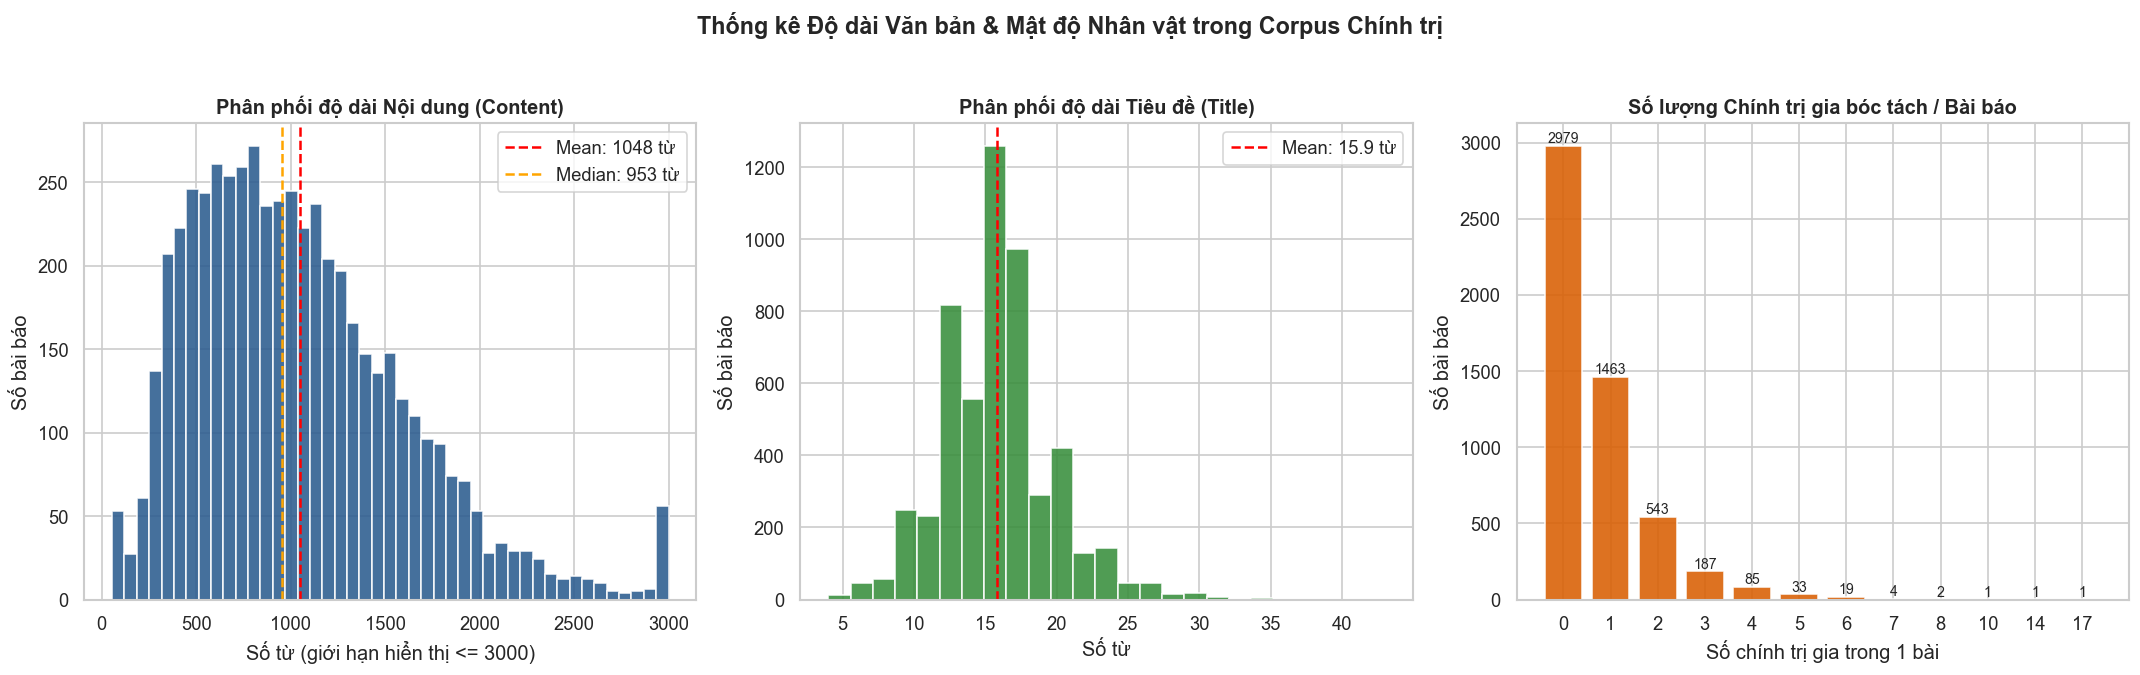

In [3]:
desc_stats = df_articles[['title_words', 'sapo_words', 'content_words', 'num_persons', 'total_mentions']].describe().T
display(desc_stats.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

axes[0].hist(df_articles['content_words'].clip(upper=3000), bins=45, color='#2b5c8f', edgecolor='white', alpha=0.88)
axes[0].axvline(df_articles['content_words'].mean(), color='red', linestyle='--', label=f"Mean: {df_articles['content_words'].mean():.0f} từ")
axes[0].axvline(df_articles['content_words'].median(), color='orange', linestyle='--', label=f"Median: {df_articles['content_words'].median():.0f} từ")
axes[0].set_title('Phân phối độ dài Nội dung (Content)', fontweight='bold')
axes[0].set_xlabel('Số từ (giới hạn hiển thị <= 3000)')
axes[0].set_ylabel('Số bài báo')
axes[0].legend()

axes[1].hist(df_articles['title_words'], bins=25, color='#388e3c', edgecolor='white', alpha=0.88)
axes[1].axvline(df_articles['title_words'].mean(), color='red', linestyle='--', label=f"Mean: {df_articles['title_words'].mean():.1f} từ")
axes[1].set_title('Phân phối độ dài Tiêu đề (Title)', fontweight='bold')
axes[1].set_xlabel('Số từ')
axes[1].set_ylabel('Số bài báo')
axes[1].legend()

person_counts_dist = df_articles['num_persons'].value_counts().sort_index().head(12)
axes[2].bar(person_counts_dist.index.astype(str), person_counts_dist.values, color='#d95f02', edgecolor='white', alpha=0.88)
axes[2].set_title('Số lượng Chính trị gia bóc tách / Bài báo', fontweight='bold')
axes[2].set_xlabel('Số chính trị gia trong 1 bài')
axes[2].set_ylabel('Số bài báo')
for i, v in enumerate(person_counts_dist.values):
    axes[2].text(i, v + 20, str(v), ha='center', fontsize=8.5)

plt.suptitle('Thống kê Độ dài Văn bản & Mật độ Nhân vật trong Corpus Chính trị', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.2. Top 20 Nguồn báo (`publisher`) đóng góp bài viết & nhân vật chính trị

,publisher,so_bai_bao,do_dai_tb,so_bai_co_nhan_vat,tong_luot_nhan_vat,ty_le_bai_%
38,Báo Tin Tức TTXVN,867,1145.971165,474,797,16.29
44,Báo VietnamPlus,482,1187.500000,281,496,9.06
13,Báo Hà Nội Mới,305,1229.895082,81,103,5.73
6,Báo Chính Phủ,300,1501.503333,161,267,5.64
39,Báo Tiền Phong,243,794.823045,110,232,4.57
8,Báo Công An Nhân Dân,196,1146.612245,91,145,3.68
28,Báo Quân Đội Nhân Dân,183,810.218579,94,166,3.44
23,Báo Nhân Dân,154,1001.883117,63,106,2.89
42,Báo VTC News,141,741.297872,52,67,2.65
43,Báo VietnamNet,138,818.405797,54,92,2.59


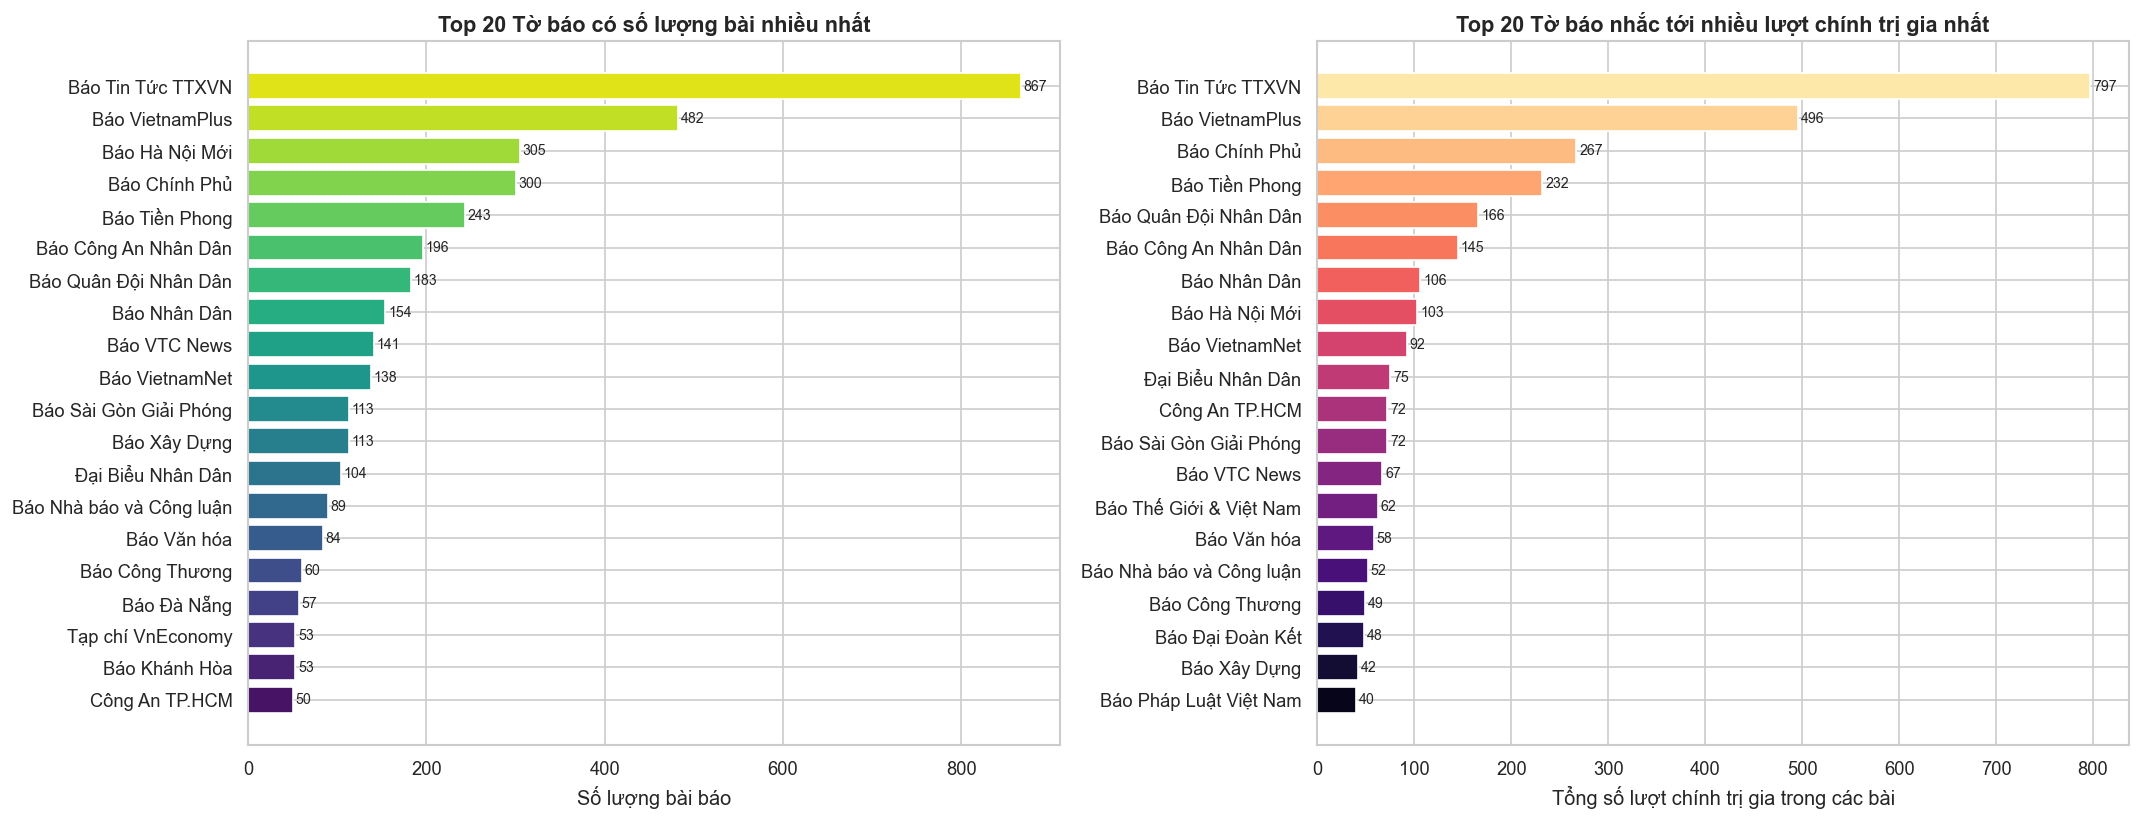

In [4]:
pub_summary = df_articles.groupby('publisher').agg(
    so_bai_bao=('article_id', 'count'),
    do_dai_tb=('content_words', 'mean'),
    so_bai_co_nhan_vat=('num_persons', lambda x: (x > 0).sum()),
    tong_luot_nhan_vat=('num_persons', 'sum')
).reset_index().sort_values('so_bai_bao', ascending=False)
pub_summary['ty_le_bai_%'] = (pub_summary['so_bai_bao'] / len(df_articles) * 100).round(2)

display(pub_summary.head(15))

top20_pub = pub_summary.head(20)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].barh(top20_pub['publisher'][::-1], top20_pub['so_bai_bao'][::-1], color=sns.color_palette('viridis', 20))
axes[0].set_title('Top 20 Tờ báo có số lượng bài nhiều nhất', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Số lượng bài báo')
for i, v in enumerate(top20_pub['so_bai_bao'][::-1]):
    axes[0].text(v + 3, i, str(v), va='center', fontsize=8.5)

top20_pub_pers = pub_summary.sort_values('tong_luot_nhan_vat', ascending=False).head(20)
axes[1].barh(top20_pub_pers['publisher'][::-1], top20_pub_pers['tong_luot_nhan_vat'][::-1], color=sns.color_palette('magma', 20))
axes[1].set_title('Top 20 Tờ báo nhắc tới nhiều lượt chính trị gia nhất', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Tổng số lượt chính trị gia trong các bài')
for i, v in enumerate(top20_pub_pers['tong_luot_nhan_vat'][::-1]):
    axes[1].text(v + 3, i, str(v), va='center', fontsize=8.5)

plt.tight_layout()
plt.show()

### 3.3. Phân tích dòng thời gian xuất bản & khung giờ đăng bài

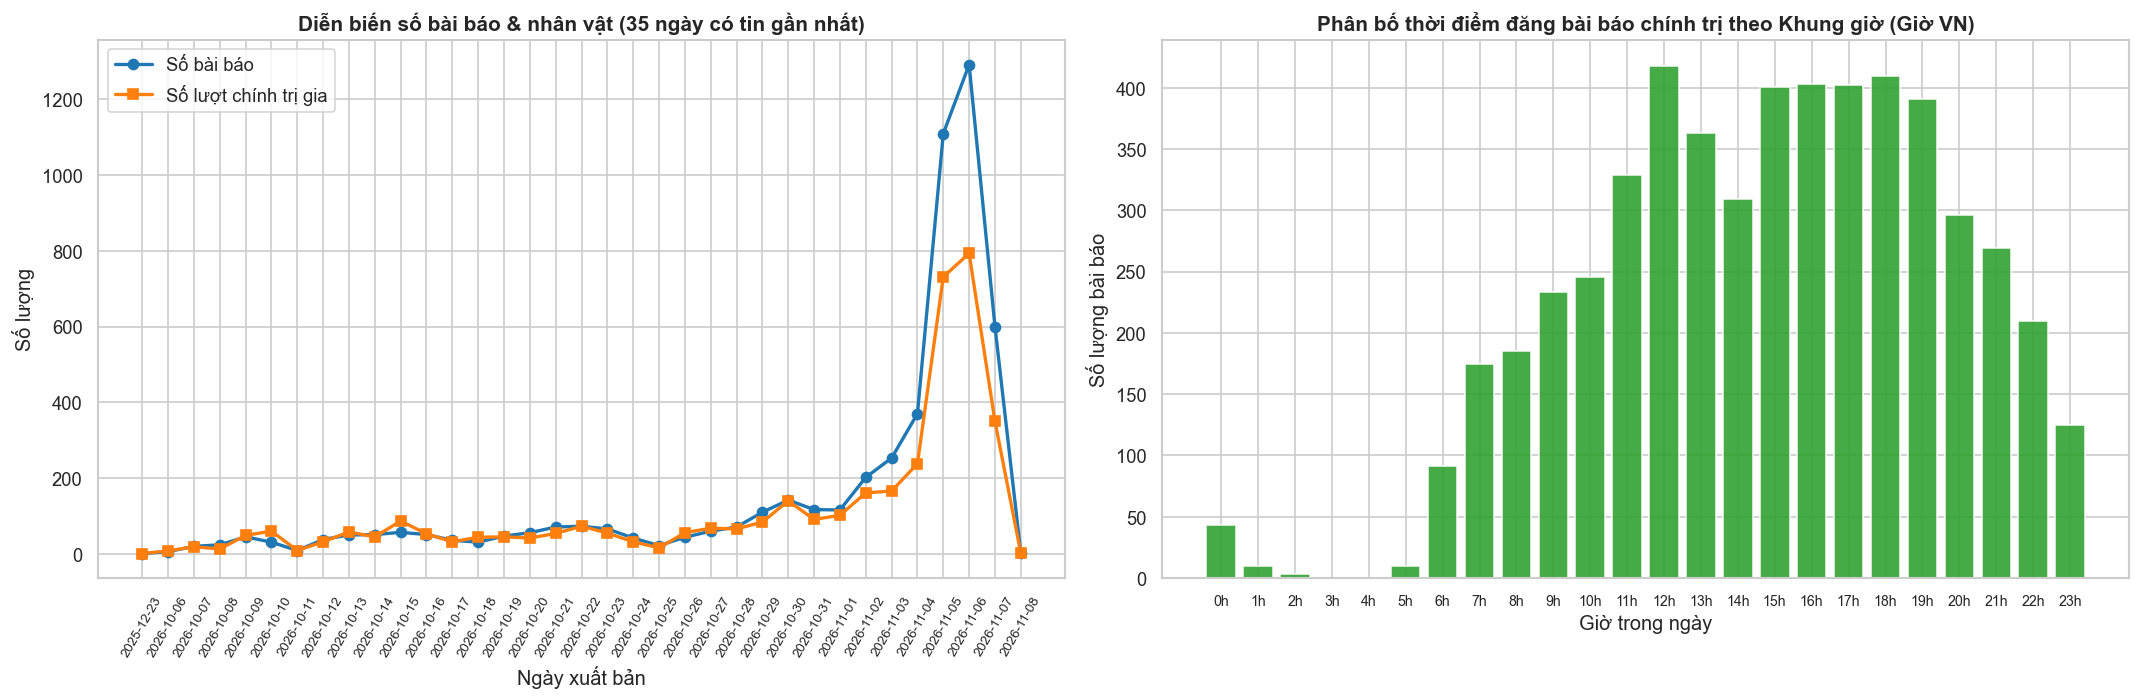

In [5]:
df_time_valid = df_articles.dropna(subset=['pub_date', 'pub_hour']).copy()

# Thống kê theo ngày (30 ngày gần nhất có nhiều bài)
daily_counts = df_time_valid.groupby('pub_date').agg(
    so_bai=('article_id', 'count'),
    so_nhan_vat=('num_persons', 'sum')
).reset_index().sort_values('pub_date')
daily_recent = daily_counts.tail(35)

hourly_counts = df_time_valid['pub_hour'].value_counts().reindex(range(24), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].plot(daily_recent['pub_date'].astype(str), daily_recent['so_bai'], marker='o', linewidth=2, color='#1f77b4', label='Số bài báo')
axes[0].plot(daily_recent['pub_date'].astype(str), daily_recent['so_nhan_vat'], marker='s', linewidth=2, color='#ff7f0e', label='Số lượt chính trị gia')
axes[0].set_title('Diễn biến số bài báo & nhân vật (35 ngày có tin gần nhất)', fontsize=12.5, fontweight='bold')
axes[0].set_xlabel('Ngày xuất bản')
axes[0].set_ylabel('Số lượng')
axes[0].tick_params(axis='x', rotation=60, labelsize=8)
axes[0].legend()

axes[1].bar(hourly_counts.index, hourly_counts.values, color='#2ca02c', edgecolor='white', alpha=0.88)
axes[1].set_xticks(range(24))
axes[1].set_xticklabels([f'{h}h' for h in range(24)], fontsize=8.5)
axes[1].set_title('Phân bố thời điểm đăng bài báo chính trị theo Khung giờ (Giờ VN)', fontsize=12.5, fontweight='bold')
axes[1].set_xlabel('Giờ trong ngày')
axes[1].set_ylabel('Số lượng bài báo')

plt.tight_layout()
plt.show()

---
## 4. PHÂN TÍCH THỐNG KÊ `baomoi_persons_political_table.json`

### 4.1. Top 25 Chính trị gia xuất hiện nhiều nhất

,person_name,tong_mention,so_bai_bao,so_lan_nv_chinh,tong_phat_ngon,chuc_vu,to_chuc
1353,Tô Lâm,531,147,103,22,"Bà brigitte haas, Bí thư, Chủ tịch nước","Ban Bí thư Trần Cẩm Tú, Ban Bí thư Trần Cẩm Tú và Bộ trưởng Chan Chun, Ban Chấp hành Trung ương Đảng"
1262,Trần Thanh Mẫn,386,154,60,7,"Chủ tịch, Chủ tịch quốc hội, Phó chủ tịch quốc hội","Ban Bí thư Trần Cẩm Tú, Ban Thường trực và toàn thể thành viên Nhóm N, Bộ Chính trị"
273,Hồ Quốc Dũng,244,83,68,13,"Bộ trưởng, Phó thủ tướng, Phó thủ tướng chính phủ","Ban Chấp hành Trung ương về xây dựng và phát, Ban Chấp hành Trung ương Đảng, Ban Chỉ đạo"
1084,Phạm Thị Thanh Trà,175,66,62,8,"Phó thủ tướng, Phó thủ tướng chính phủ, Trưởng ban","Ban Bí thư Trần Cẩm Tú, Ban Chấp hành Trung ương Đảng khóa XIV, Ban Chấp hành Trung ương Đảng khóa XIV về thu"
491,Lương Tam Quang,160,36,33,10,Bộ trưởng,"Bộ Chính trị, Bộ Chính trị về khẩn trương xây dựng, Bộ Chính trị về khẩn trương xây dựng triển k"
372,Lê Minh Hưng,157,41,27,9,"Chủ tịch quốc hội, Thủ tướng, Trưởng ban","Ban Chỉ đạo 57 Trung ương ngày 28/9/2026, Ban Chỉ đạo Trung ương thực hiện Chương trình, Ban Chỉ đạo cấp tỉnh theo Q..."
424,Lê Tiến Châu,155,48,42,6,"Phó thủ tướng, Phó thủ tướng chính phủ","Ban Chỉ đạo Trung ương về phát triển khoa học, Ban Thường vụ Tỉnh uỷ Nghệ An, Ban Thường vụ Tỉnh uỷ Quảng Trị"
1209,Trần Cẩm Tú,141,44,30,8,"Phó thủ tướng chính phủ, Thường trực ban bí thư, Trưởng ban c","Ban Bí thư, Ban Bí thư Trần Cẩm Tú, Ban Bí thư Trần Cẩm Tú bày tỏ tin tưởng"
555,Nguyễn Bá Hoan,138,14,14,17,Thứ trưởng,"Bộ Lao động - Thương binh và Xã hội, Bộ Lao động - Thương binh và Xã hội Nguyễn B, Bộ Lao động - Thương binh và Xã h..."
269,Hồ Chí Minh,133,16,12,7,"Chủ tịch, Phó chủ tịch ủy ban nhân dân, Tổng bí thư","Ban Thường trực Quốc hội Bùi Bằng Đoàn cùng h, Ban Thường vụ Tỉnh ủy Khánh Hòa chỉ đạo nội d, Ban Tuyên giáo Thành ủ..."


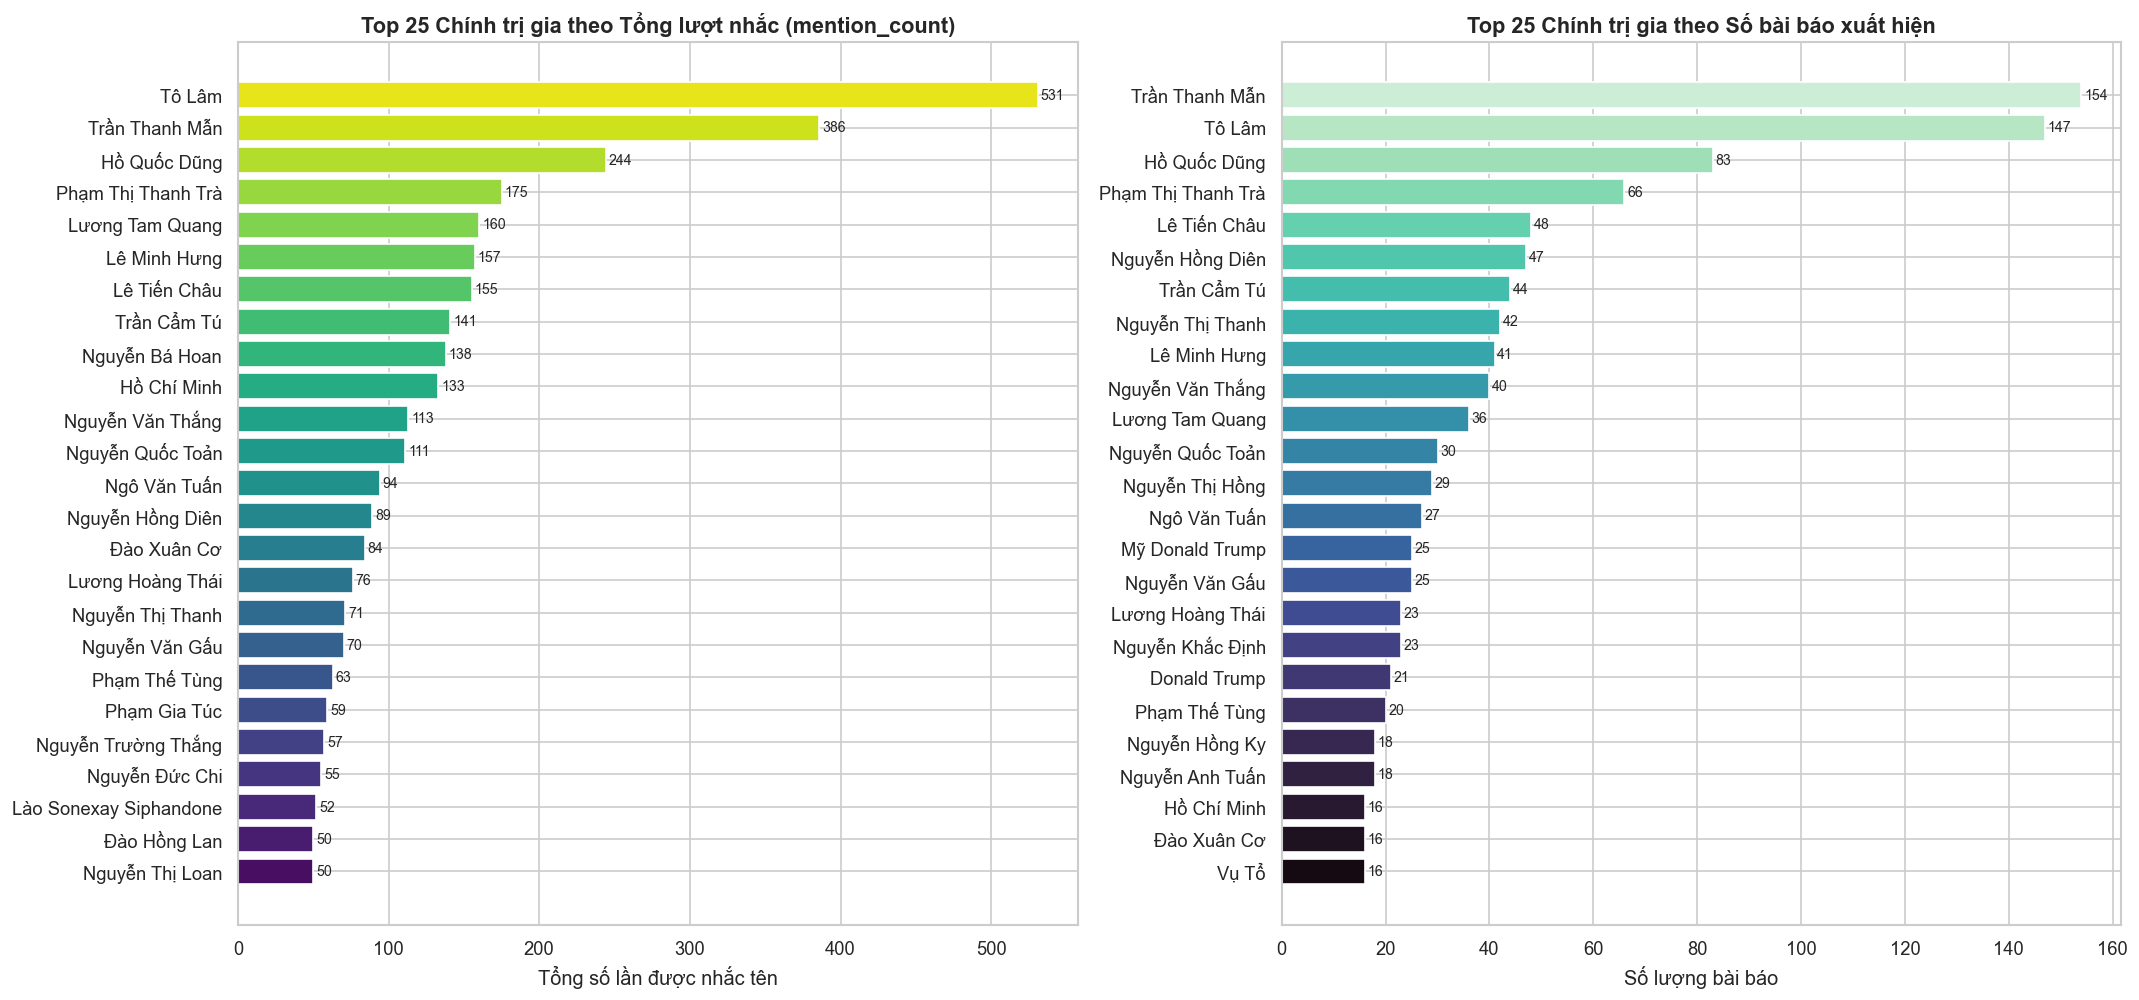

In [6]:
person_stats = df_persons.groupby('person_name').agg(
    tong_mention=('mention_count', 'sum'),
    so_bai_bao=('article_id', 'nunique'),
    so_lan_nv_chinh=('is_main_character', lambda x: sum(bool(v) for v in x)),
    tong_phat_ngon=('quotes_count', 'sum'),
    chuc_vu=('role_title', lambda x: ', '.join(sorted(set(t.strip() for v in x if v for t in str(v).split(',') if t.strip()))[:3])),
    to_chuc=('organization', lambda x: ', '.join(sorted(set(t.strip() for v in x if v for t in str(v).split(',') if t.strip()))[:3]))
).reset_index().sort_values(['tong_mention', 'so_bai_bao'], ascending=False)

display(person_stats.head(25))

top25_pers = person_stats.head(25)
fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))

axes[0].barh(top25_pers['person_name'][::-1], top25_pers['tong_mention'][::-1], color=sns.color_palette('viridis', 25))
axes[0].set_title('Top 25 Chính trị gia theo Tổng lượt nhắc (mention_count)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tổng số lần được nhắc tên')
for i, v in enumerate(top25_pers['tong_mention'][::-1]):
    axes[0].text(v + 2, i, str(v), va='center', fontsize=8.5)

top25_by_art = person_stats.sort_values('so_bai_bao', ascending=False).head(25)
axes[1].barh(top25_by_art['person_name'][::-1], top25_by_art['so_bai_bao'][::-1], color=sns.color_palette('mako', 25))
axes[1].set_title('Top 25 Chính trị gia theo Số bài báo xuất hiện', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Số lượng bài báo')
for i, v in enumerate(top25_by_art['so_bai_bao'][::-1]):
    axes[1].text(v + 0.5, i, str(v), va='center', fontsize=8.5)

plt.tight_layout()
plt.show()

### 4.2. Thống kê Chức vụ (`role_title`), Tổ chức (`organization`) và Phát ngôn (`quotes`)

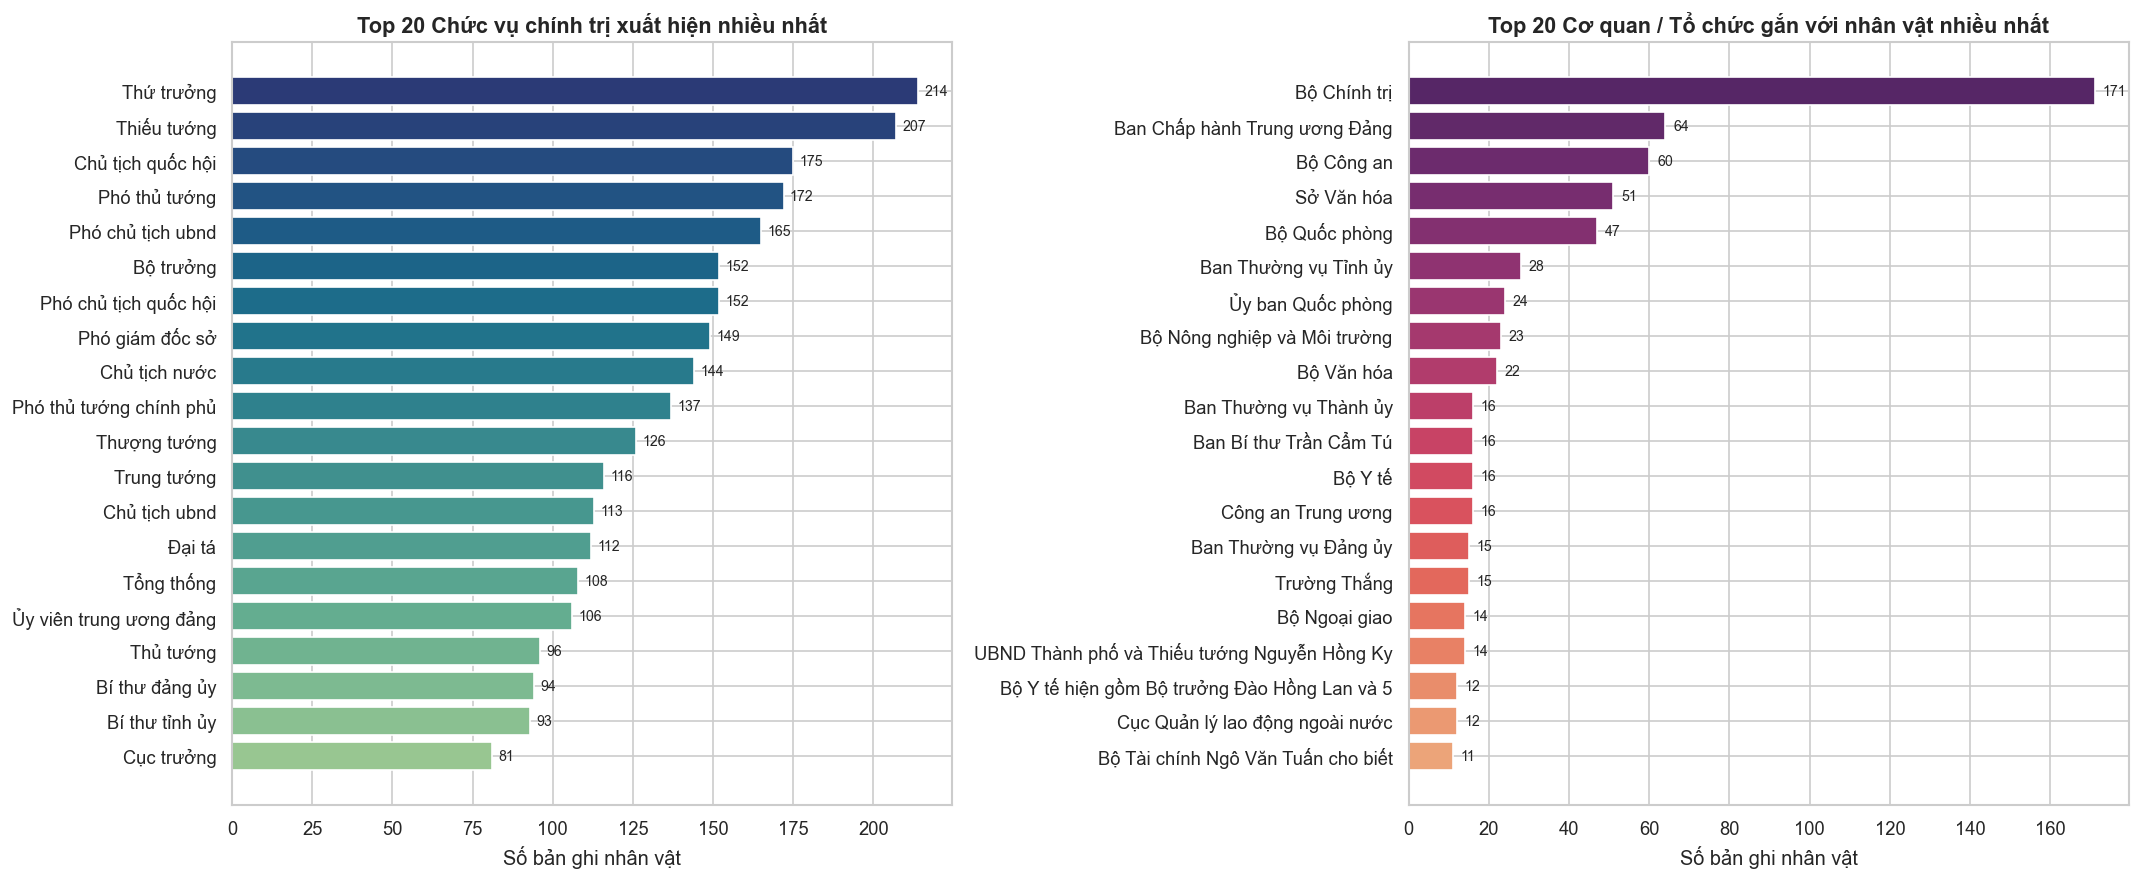

Top 10 Chính trị gia có nhiều câu trích dẫn phát ngôn trực tiếp nhất:


,person_name,tong_phat_ngon,so_bai_bao,chuc_vu
1353,Tô Lâm,22,147,"Bà brigitte haas, Bí thư, Chủ tịch nước"
555,Nguyễn Bá Hoan,17,14,Thứ trưởng
720,Nguyễn Quốc Toản,16,30,"Chánh văn phòng, Thiếu tướng"
273,Hồ Quốc Dũng,13,83,"Bộ trưởng, Phó thủ tướng, Phó thủ tướng chính phủ"
491,Lương Tam Quang,10,36,Bộ trưởng
423,Lê Thị Ánh Mai,10,9,Phó giám đốc sở
372,Lê Minh Hưng,9,41,"Chủ tịch quốc hội, Thủ tướng, Trưởng ban"
1224,Trần Hữu Linh,9,9,Cục trưởng
835,Nguyễn Trường Thắng,9,14,"Thượng tướng, Thứ trưởng, Ủy viên trung ương đảng"
869,Nguyễn Văn Gấu,9,25,"Thượng tướng, Thứ trưởng, Thứ trưởng b"


In [7]:
# Tách từng chức vụ và từng tổ chức
role_counter = Counter()
org_counter = Counter()

for _, row in df_persons.iterrows():
    for r in str(row.get('role_title', '')).split(','):
        r_clean = r.strip()
        if r_clean:
            role_counter[r_clean] += 1
    for o in str(row.get('organization', '')).split(','):
        o_clean = o.strip()
        if o_clean and len(o_clean) > 3:
            org_counter[o_clean] += 1

df_roles = pd.DataFrame(role_counter.most_common(20), columns=['Chức vụ', 'Số hồ sơ'])
df_orgs = pd.DataFrame(org_counter.most_common(20), columns=['Cơ quan / Tổ chức', 'Số hồ sơ'])

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

axes[0].barh(df_roles['Chức vụ'][::-1], df_roles['Số hồ sơ'][::-1], color=sns.color_palette('crest', 20))
axes[0].set_title('Top 20 Chức vụ chính trị xuất hiện nhiều nhất', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Số bản ghi nhân vật')
for i, v in enumerate(df_roles['Số hồ sơ'][::-1]):
    axes[0].text(v + 2, i, str(v), va='center', fontsize=8.5)

axes[1].barh(df_orgs['Cơ quan / Tổ chức'][::-1], df_orgs['Số hồ sơ'][::-1], color=sns.color_palette('flare', 20))
axes[1].set_title('Top 20 Cơ quan / Tổ chức gắn với nhân vật nhiều nhất', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Số bản ghi nhân vật')
for i, v in enumerate(df_orgs['Số hồ sơ'][::-1]):
    axes[1].text(v + 2, i, str(v), va='center', fontsize=8.5)

plt.tight_layout()
plt.show()

print('Top 10 Chính trị gia có nhiều câu trích dẫn phát ngôn trực tiếp nhất:')
display(person_stats.sort_values('tong_phat_ngon', ascending=False)[['person_name', 'tong_phat_ngon', 'so_bai_bao', 'chuc_vu']].head(10))

---
## 5. PHÂN TÍCH ĐỒ THỊ QUAN HỆ CHÍNH TRỊ GIA (KNOWLEDGE GRAPH)

Quy tắc xây dựng đồ thị:
- **Đỉnh (Node):** Mỗi chính trị gia duy nhất (`person_name`).
- **Cạnh (Edge):** Hai chính trị gia có cạnh nối nếu cùng xuất hiện trong ít nhất 1 bài báo (`article_id`).
- **Trọng số cạnh (`weight`):** Số bài báo mà hai chính trị gia cùng xuất hiện.

### 5.1. Xây dựng Đồ thị & Thống kê cấu trúc mạng lưới

In [8]:
# Gom danh sách nhân vật duy nhất theo mỗi bài báo
art_to_persons = df_persons.groupby('article_id')['person_name'].apply(lambda s: sorted(set(s))).reset_index()
art_multi = art_to_persons[art_to_persons['person_name'].apply(len) >= 2].copy()

edge_counter = Counter()
for persons_list in art_multi['person_name']:
    for pair in combinations(persons_list, 2):
        edge_counter[pair] += 1

# Khởi tạo đồ thị vô hướng có trọng số
G = nx.Graph()

# Bổ sung thuộc tính số lần xuất hiện cho từng node
mention_lookup = dict(zip(person_stats['person_name'], person_stats['tong_mention']))
article_lookup = dict(zip(person_stats['person_name'], person_stats['so_bai_bao']))

for (u, v), w in edge_counter.items():
    G.add_edge(u, v, weight=w)

for n in G.nodes():
    G.nodes[n]['mentions'] = int(mention_lookup.get(n, 1))
    G.nodes[n]['articles'] = int(article_lookup.get(n, 1))

components = sorted(nx.connected_components(G), key=len, reverse=True)
G_giant = G.subgraph(components[0]).copy() if components else G

print('📊 THỐNG KÊ CẤU TRÚC ĐỒ THỊ QUAN HỆ (CO-OCCURRENCE GRAPH):')
print(f'   - Số bài báo có >= 2 chính trị gia: {len(art_multi):,} bài')
print(f'   - Số đỉnh (Nodes - chính trị gia có liên kết): {G.number_of_nodes():,}')
print(f'   - Số cạnh (Edges - cặp quan hệ duy nhất): {G.number_of_edges():,}')
print(f'   - Tổng trọng số cạnh (Tổng lượt đồng xuất hiện): {sum(edge_counter.values()):,}')
print(f'   - Mật độ đồ thị (Graph Density): {nx.density(G):.5f}')
print(f'   - Hệ số phân cụm trung bình (Avg Clustering Coefficient): {nx.average_clustering(G):.4f}')
print(f'   - Số thành phần liên thông (Connected Components): {len(components)}')
print(f'   - Thành phần liên thông lớn nhất (Giant Component): {G_giant.number_of_nodes()} đỉnh ({G_giant.number_of_nodes()/G.number_of_nodes()*100:.1f}%), {G_giant.number_of_edges()} cạnh')

📊 THỐNG KÊ CẤU TRÚC ĐỒ THỊ QUAN HỆ (CO-OCCURRENCE GRAPH):
   - Số bài báo có >= 2 chính trị gia: 880 bài
   - Số đỉnh (Nodes - chính trị gia có liên kết): 1,172
   - Số cạnh (Edges - cặp quan hệ duy nhất): 2,561
   - Tổng trọng số cạnh (Tổng lượt đồng xuất hiện): 3,423
   - Mật độ đồ thị (Graph Density): 0.00373
   - Hệ số phân cụm trung bình (Avg Clustering Coefficient): 0.5317
   - Số thành phần liên thông (Connected Components): 201
   - Thành phần liên thông lớn nhất (Giant Component): 592 đỉnh (50.5%), 1821 cạnh


### 5.2. Phân tích Số lượng cạnh (Degree & Weighted Degree) và Phân phối Bậc

,person_name,degree,weighted_degree,betweenness,closeness,pagerank,so_bai_bao,tong_mention
2,Tô Lâm,84,179,0.127344,0.203462,0.016264,147,531
1,Trần Thanh Mẫn,73,216,0.035651,0.178288,0.017728,154,386
14,Phạm Thị Thanh Trà,39,50,0.031428,0.175560,0.004615,66,175
46,Nguyễn Văn Gấu,35,68,0.017479,0.148101,0.004876,25,70
58,Hồ Quốc Dũng,35,54,0.025304,0.176808,0.005474,83,244
6,Lê Minh Hưng,33,52,0.014768,0.162371,0.004970,41,157
813,Trần Thanh Hải,29,44,0.030094,0.156822,0.002066,9,10
60,Mỹ Donald Trump,28,34,0.024869,0.153040,0.004298,25,30
372,Lê Quốc Hùng,25,42,0.004419,0.144304,0.002985,12,40
366,Nguyễn Huy Dũng,25,27,0.009420,0.142784,0.002183,5,10


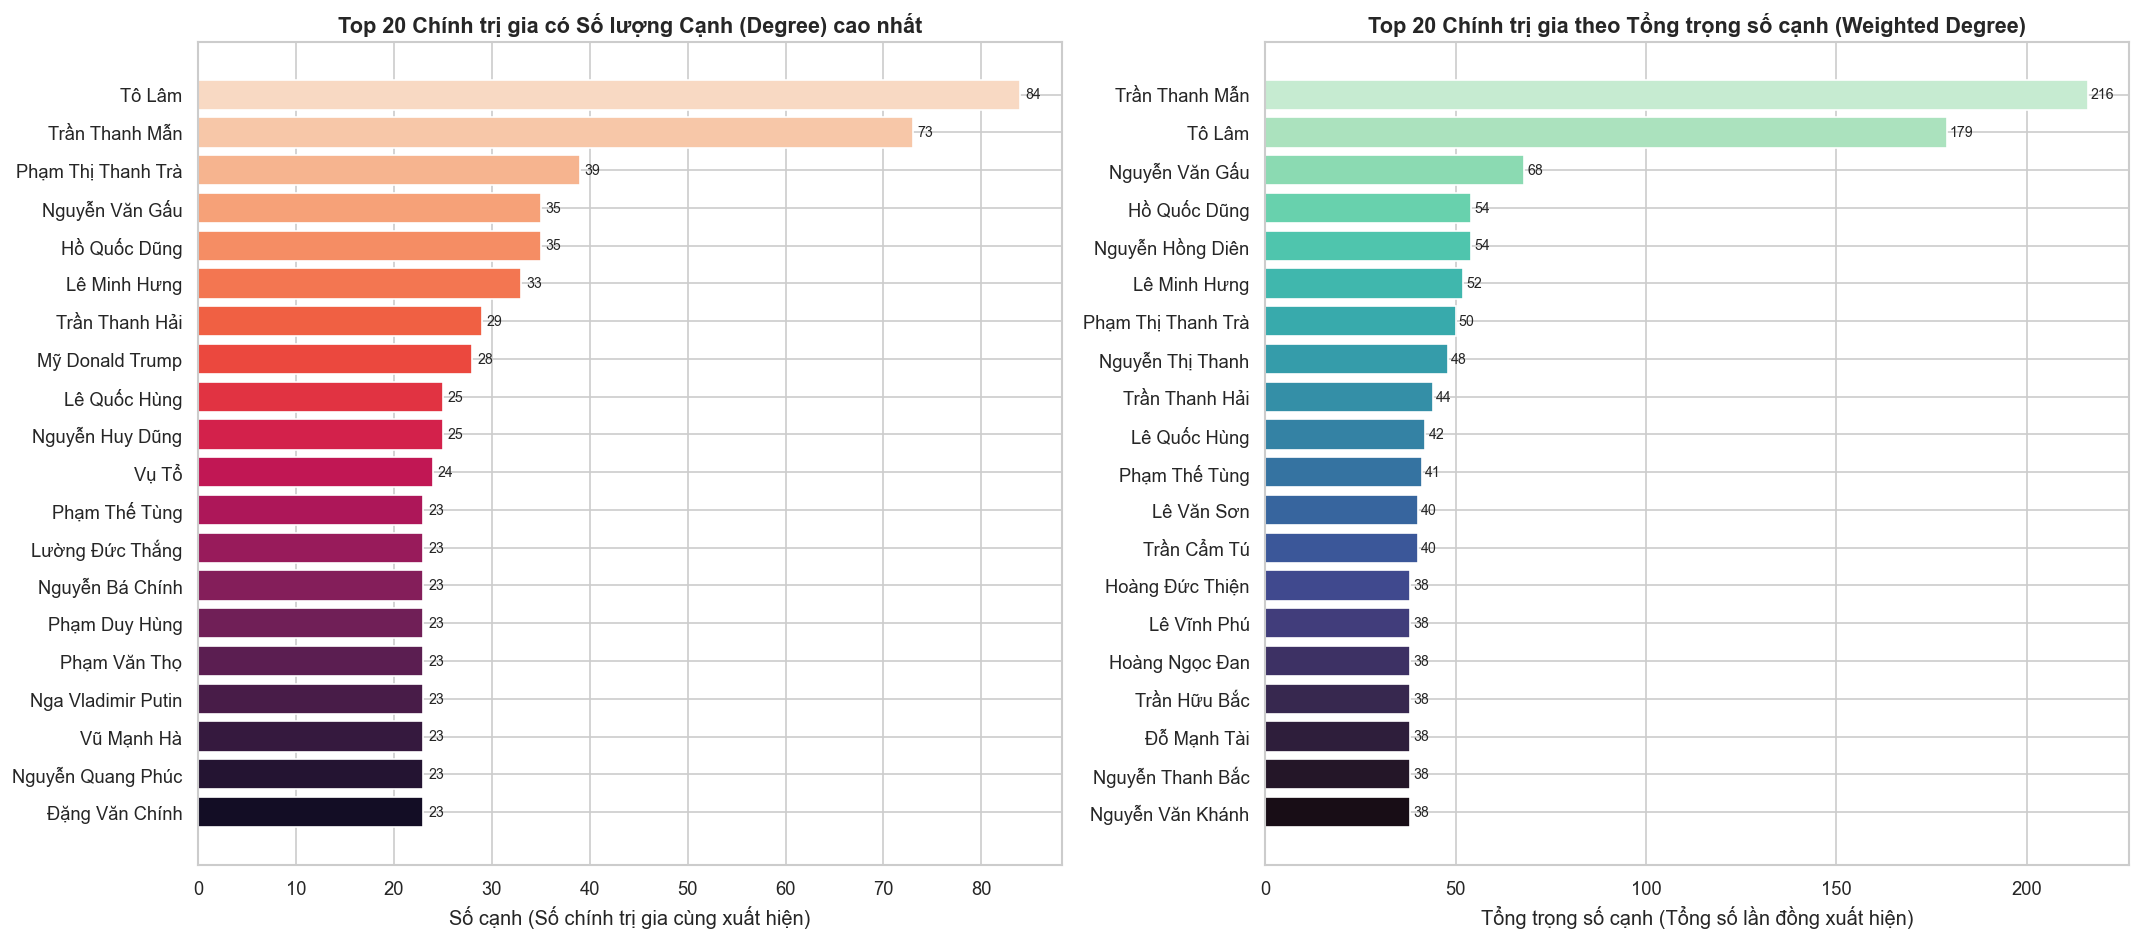

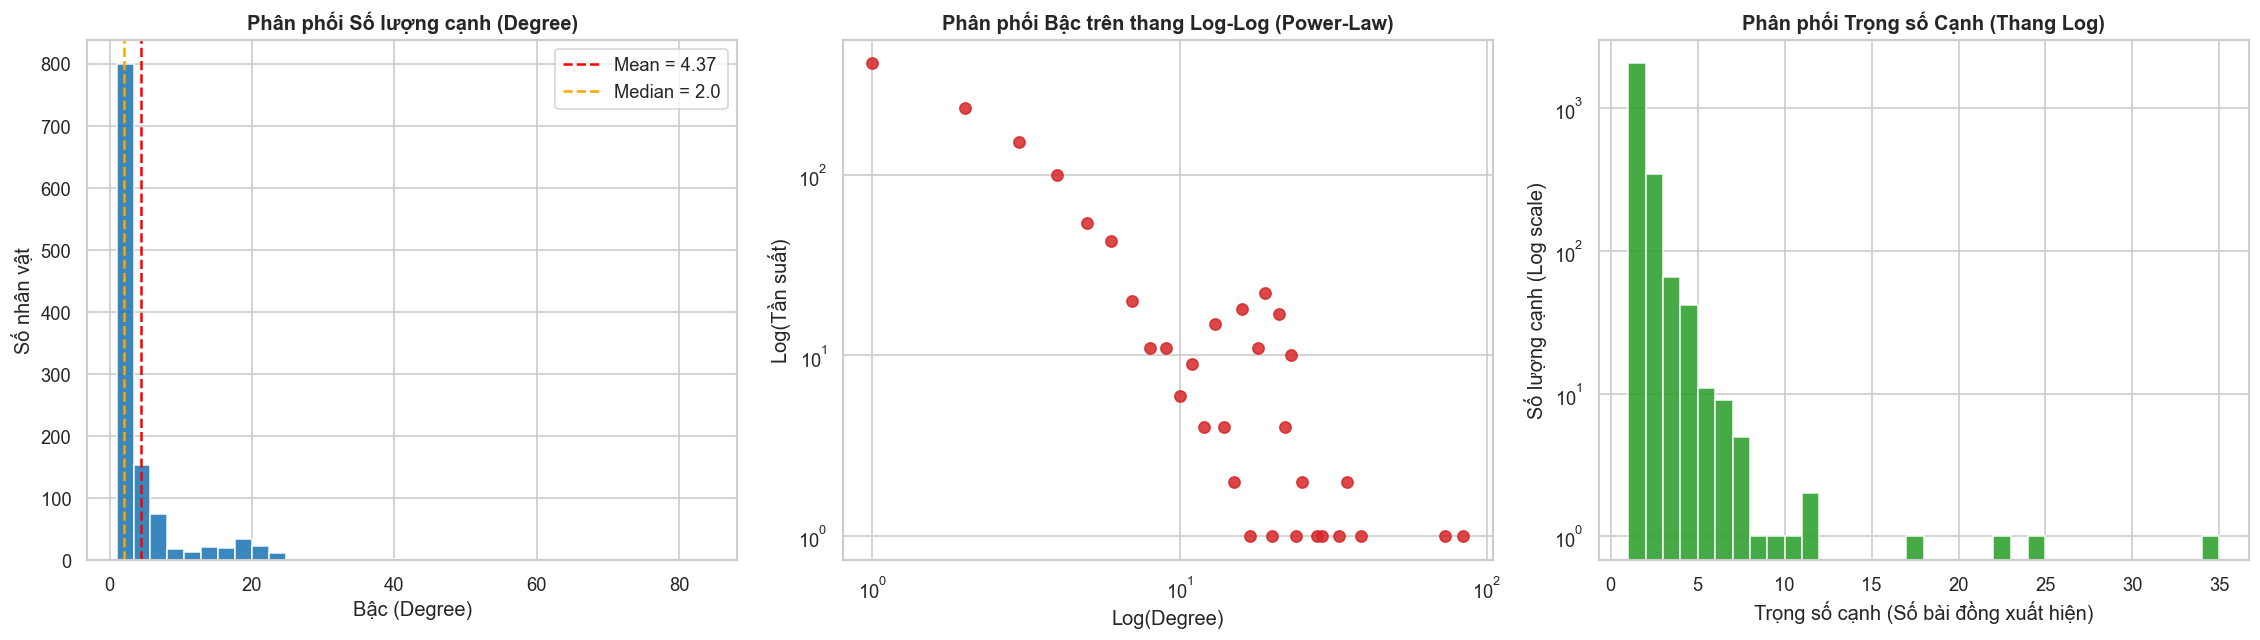

In [9]:
degree_dict = dict(G.degree())
w_degree_dict = dict(G.degree(weight='weight'))
betweenness_dict = nx.betweenness_centrality(G, weight='weight')
closeness_dict = nx.closeness_centrality(G)
pagerank_dict = nx.pagerank(G, weight='weight')

df_graph_metrics = pd.DataFrame({
    'person_name': list(G.nodes()),
    'degree': [degree_dict[n] for n in G.nodes()],
    'weighted_degree': [w_degree_dict[n] for n in G.nodes()],
    'betweenness': [betweenness_dict[n] for n in G.nodes()],
    'closeness': [closeness_dict[n] for n in G.nodes()],
    'pagerank': [pagerank_dict[n] for n in G.nodes()],
    'so_bai_bao': [G.nodes[n]['articles'] for n in G.nodes()],
    'tong_mention': [G.nodes[n]['mentions'] for n in G.nodes()]
}).sort_values(['degree', 'weighted_degree'], ascending=False)

display(df_graph_metrics.head(20))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

top20_deg = df_graph_metrics.head(20)
axes[0].barh(top20_deg['person_name'][::-1], top20_deg['degree'][::-1], color=sns.color_palette('rocket', 20))
axes[0].set_title('Top 20 Chính trị gia có Số lượng Cạnh (Degree) cao nhất', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Số cạnh (Số chính trị gia cùng xuất hiện)')
for i, v in enumerate(top20_deg['degree'][::-1]):
    axes[0].text(v + 0.5, i, str(v), va='center', fontsize=8.5)

top20_wdeg = df_graph_metrics.sort_values('weighted_degree', ascending=False).head(20)
axes[1].barh(top20_wdeg['person_name'][::-1], top20_wdeg['weighted_degree'][::-1], color=sns.color_palette('mako', 20))
axes[1].set_title('Top 20 Chính trị gia theo Tổng trọng số cạnh (Weighted Degree)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Tổng trọng số cạnh (Tổng số lần đồng xuất hiện)')
for i, v in enumerate(top20_wdeg['weighted_degree'][::-1]):
    axes[1].text(v + 0.8, i, str(v), va='center', fontsize=8.5)

plt.tight_layout()
plt.show()

# Phân phối bậc (Degree Distribution) và Trọng số cạnh
degrees = df_graph_metrics['degree'].values
edge_weights = [d['weight'] for _, _, d in G.edges(data=True)]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

axes[0].hist(degrees, bins=35, color='#1f77b4', edgecolor='white', alpha=0.88)
axes[0].axvline(np.mean(degrees), color='red', linestyle='--', label=f'Mean = {np.mean(degrees):.2f}')
axes[0].axvline(np.median(degrees), color='orange', linestyle='--', label=f'Median = {np.median(degrees):.1f}')
axes[0].set_title('Phân phối Số lượng cạnh (Degree)', fontweight='bold')
axes[0].set_xlabel('Bậc (Degree)')
axes[0].set_ylabel('Số nhân vật')
axes[0].legend()

deg_counts = Counter(degrees)
x_deg = sorted(deg_counts.keys())
y_freq = [deg_counts[k] for k in x_deg]
axes[1].scatter(x_deg, y_freq, color='#d62728', s=45, alpha=0.85)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Phân phối Bậc trên thang Log-Log (Power-Law)', fontweight='bold')
axes[1].set_xlabel('Log(Degree)')
axes[1].set_ylabel('Log(Tần suất)')

axes[2].hist(edge_weights, bins=range(1, max(edge_weights) + 2), color='#2ca02c', edgecolor='white', alpha=0.88)
axes[2].set_yscale('log')
axes[2].set_title('Phân phối Trọng số Cạnh (Thang Log)', fontweight='bold')
axes[2].set_xlabel('Trọng số cạnh (Số bài đồng xuất hiện)')
axes[2].set_ylabel('Số lượng cạnh (Log scale)')

plt.tight_layout()
plt.show()

### 5.3. Top 25 Cặp Chính trị gia có mối liên hệ mạnh nhất (Trọng số cạnh lớn nhất)

,Nhân vật 1,Nhân vật 2,Số bài đồng xuất hiện (Weight),Degree NV1,Degree NV2
0,Trần Thanh Mẫn,Tô Lâm,34,73,84
1,Nguyễn Thị Thanh,Trần Thanh Mẫn,24,19,73
2,Nguyễn Hồng Diên,Trần Thanh Mẫn,22,18,73
3,Nguyễn Khắc Định,Trần Thanh Mẫn,17,14,73
4,Lê Minh Hưng,Tô Lâm,11,33,84
5,Nguyễn Thị Hồng,Trần Thanh Mẫn,11,15,73
6,Trần Cẩm Tú,Tô Lâm,10,17,84
7,Nguyễn Văn Gấu,Trần Chí Tâm,9,35,6
8,Trần Cẩm Tú,Trần Thanh Mẫn,8,17,73
9,Lê Quốc Hùng,Nguyễn Văn Gấu,7,25,35


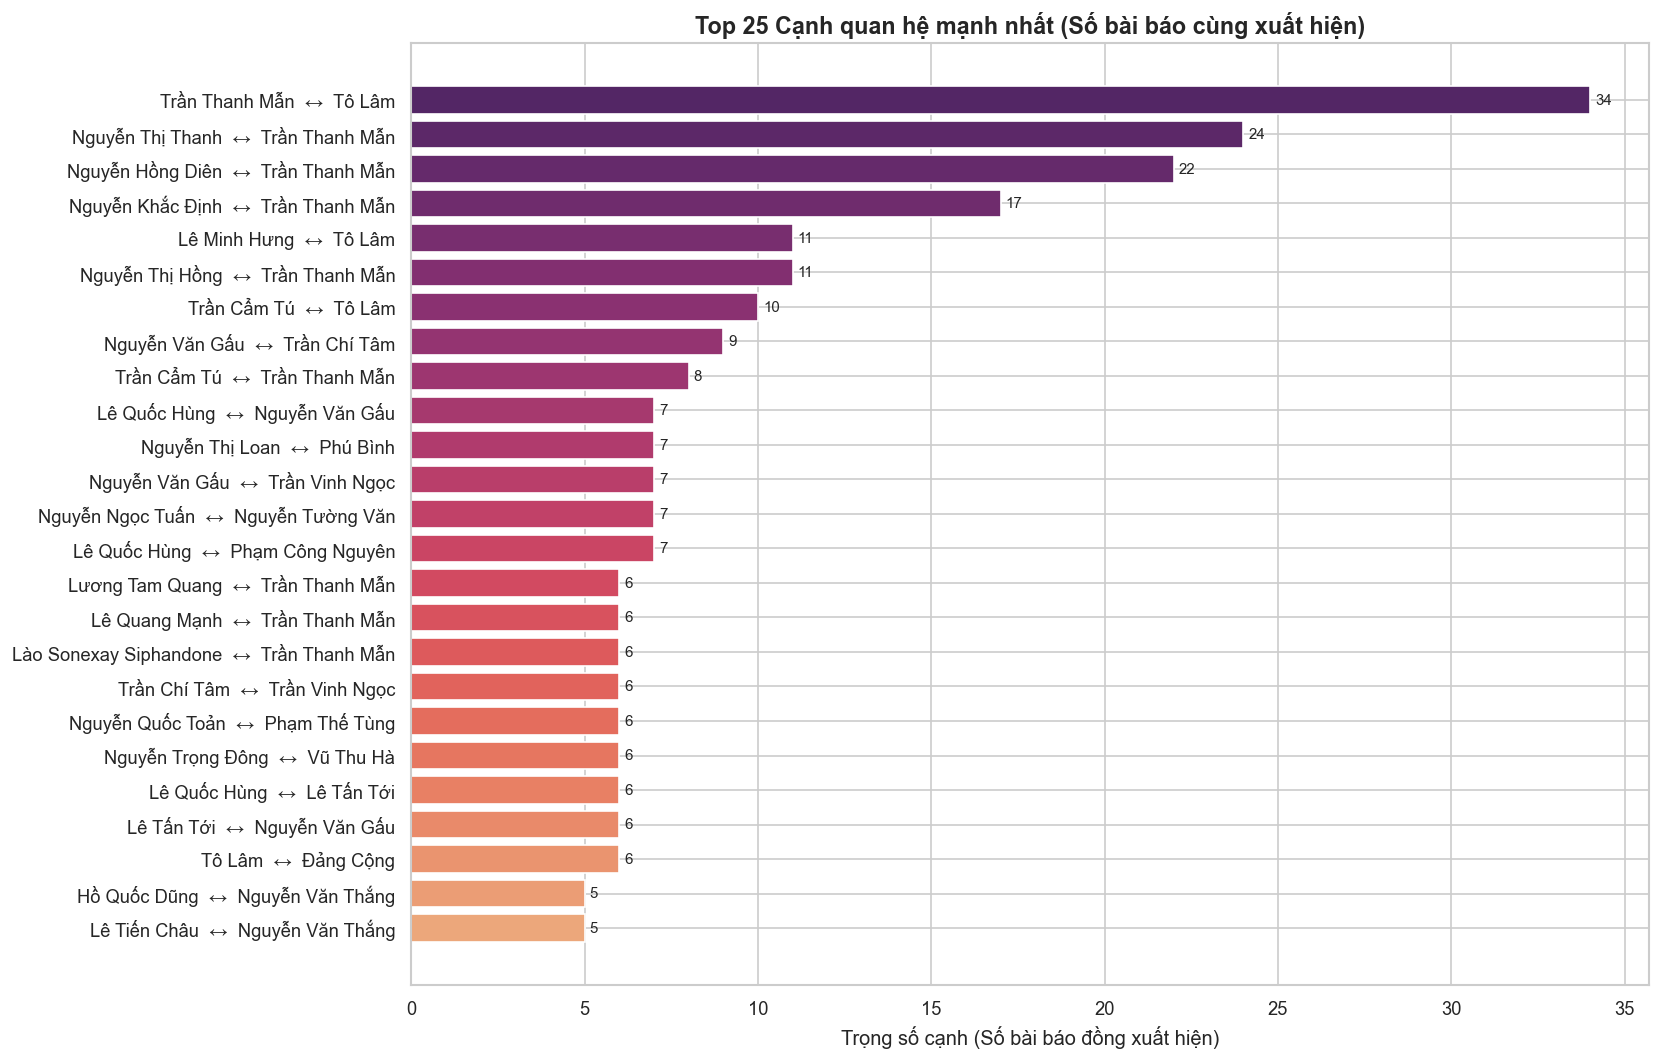

In [10]:
top25_edges = edge_counter.most_common(25)
df_top_edges = pd.DataFrame([
    {'Nhân vật 1': u, 'Nhân vật 2': v, 'Số bài đồng xuất hiện (Weight)': w,
     'Degree NV1': degree_dict[u], 'Degree NV2': degree_dict[v]}
    for (u, v), w in top25_edges
])
display(df_top_edges)

edge_labels = [f"{r['Nhân vật 1']}  ↔  {r['Nhân vật 2']}" for _, r in df_top_edges.iterrows()]
fig, ax = plt.subplots(figsize=(14, 9))
bars = ax.barh(edge_labels[::-1], df_top_edges['Số bài đồng xuất hiện (Weight)'][::-1], color=sns.color_palette('flare', 25))
ax.set_title('Top 25 Cạnh quan hệ mạnh nhất (Số bài báo cùng xuất hiện)', fontsize=14, fontweight='bold')
ax.set_xlabel('Trọng số cạnh (Số bài báo đồng xuất hiện)')
for bar, val in zip(bars, df_top_edges['Số bài đồng xuất hiện (Weight)'][::-1]):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=9)
plt.tight_layout()
plt.show()

### 5.4. So sánh các chỉ số Độ trung tâm (Betweenness, Closeness, PageRank)

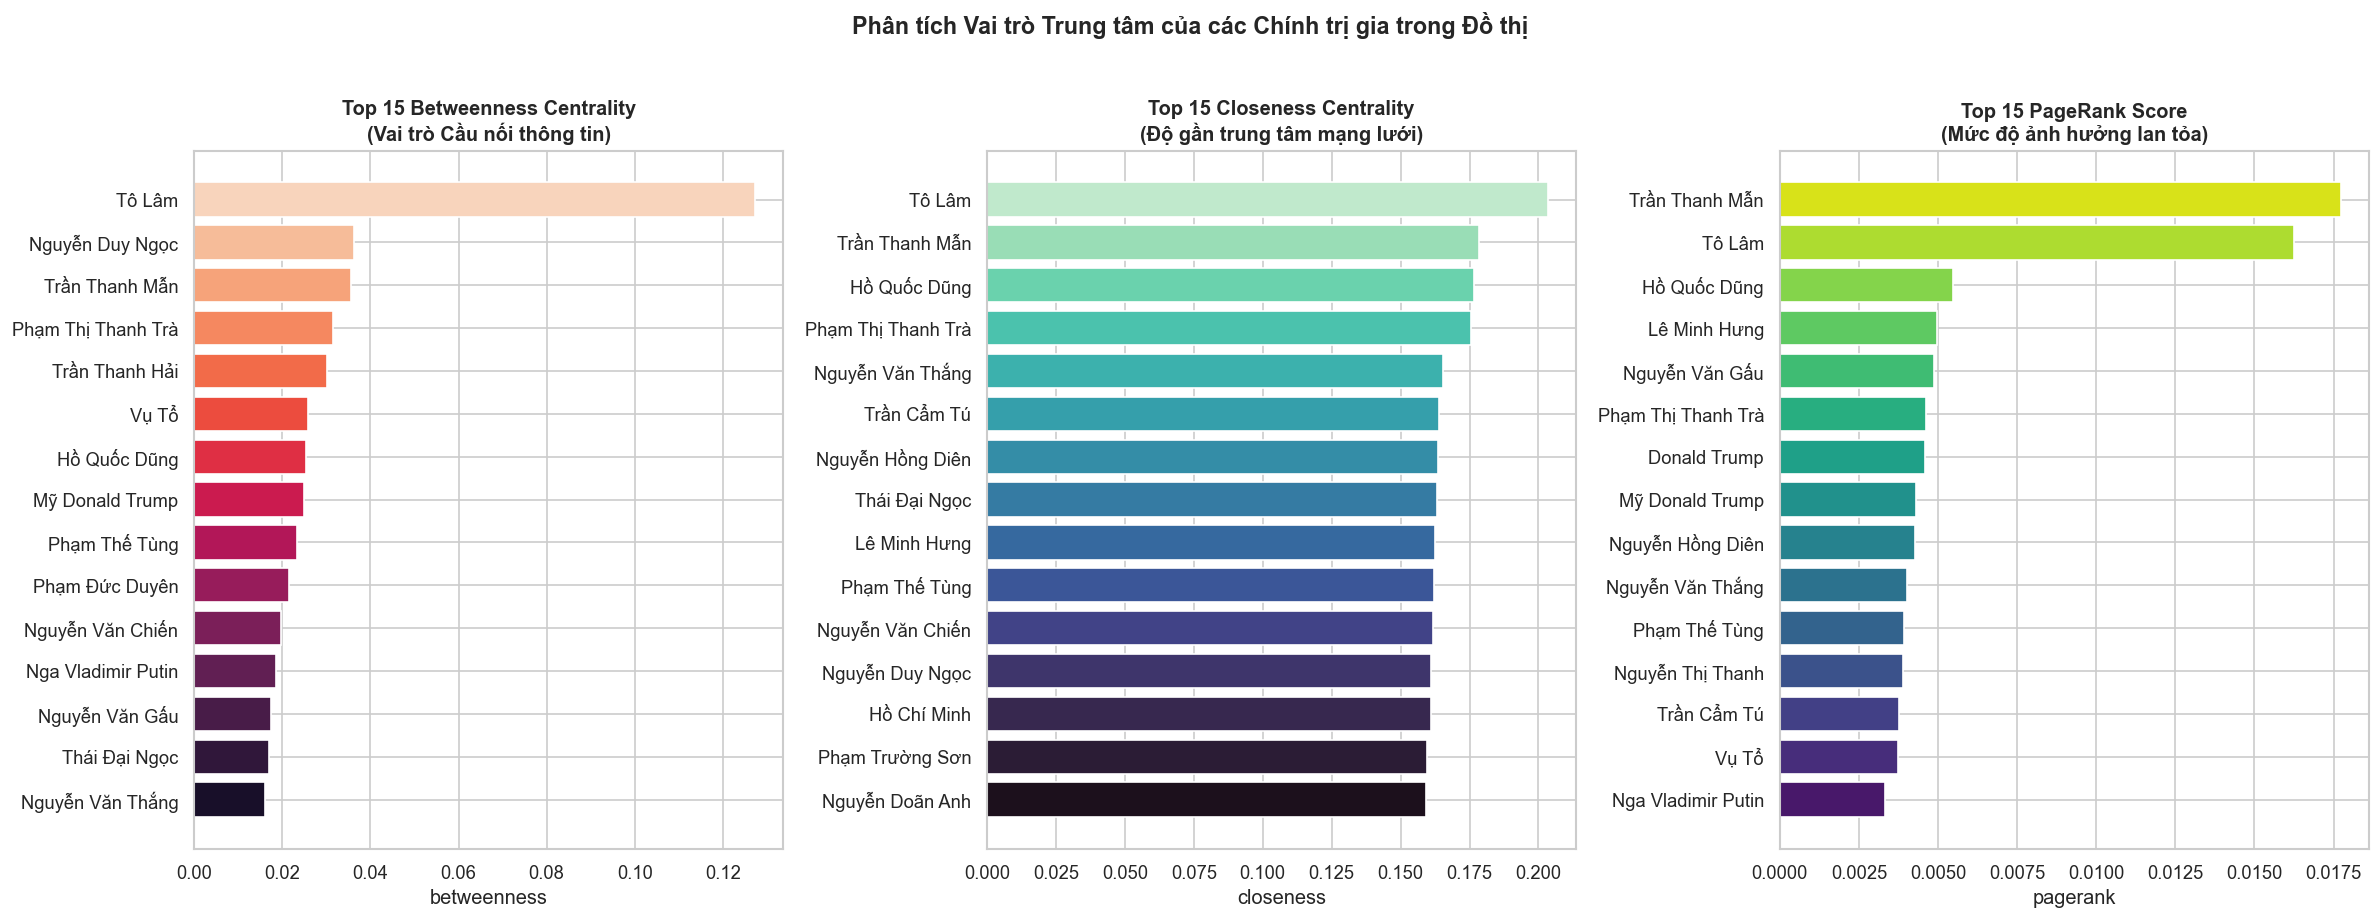

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7.5))

for idx, (col, title, pal) in enumerate([
    ('betweenness', 'Top 15 Betweenness Centrality\n(Vai trò Cầu nối thông tin)', 'rocket'),
    ('closeness', 'Top 15 Closeness Centrality\n(Độ gần trung tâm mạng lưới)', 'mako'),
    ('pagerank', 'Top 15 PageRank Score\n(Mức độ ảnh hưởng lan tỏa)', 'viridis')
]):
    sub_df = df_graph_metrics.sort_values(col, ascending=False).head(15)
    axes[idx].barh(sub_df['person_name'][::-1], sub_df[col][::-1], color=sns.color_palette(pal, 15))
    axes[idx].set_title(title, fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)

plt.suptitle('Phân tích Vai trò Trung tâm của các Chính trị gia trong Đồ thị', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 5.5. Trực quan hóa Đồ thị Mạng lưới Quan hệ (Top 35 Chính trị gia có bậc cao nhất)

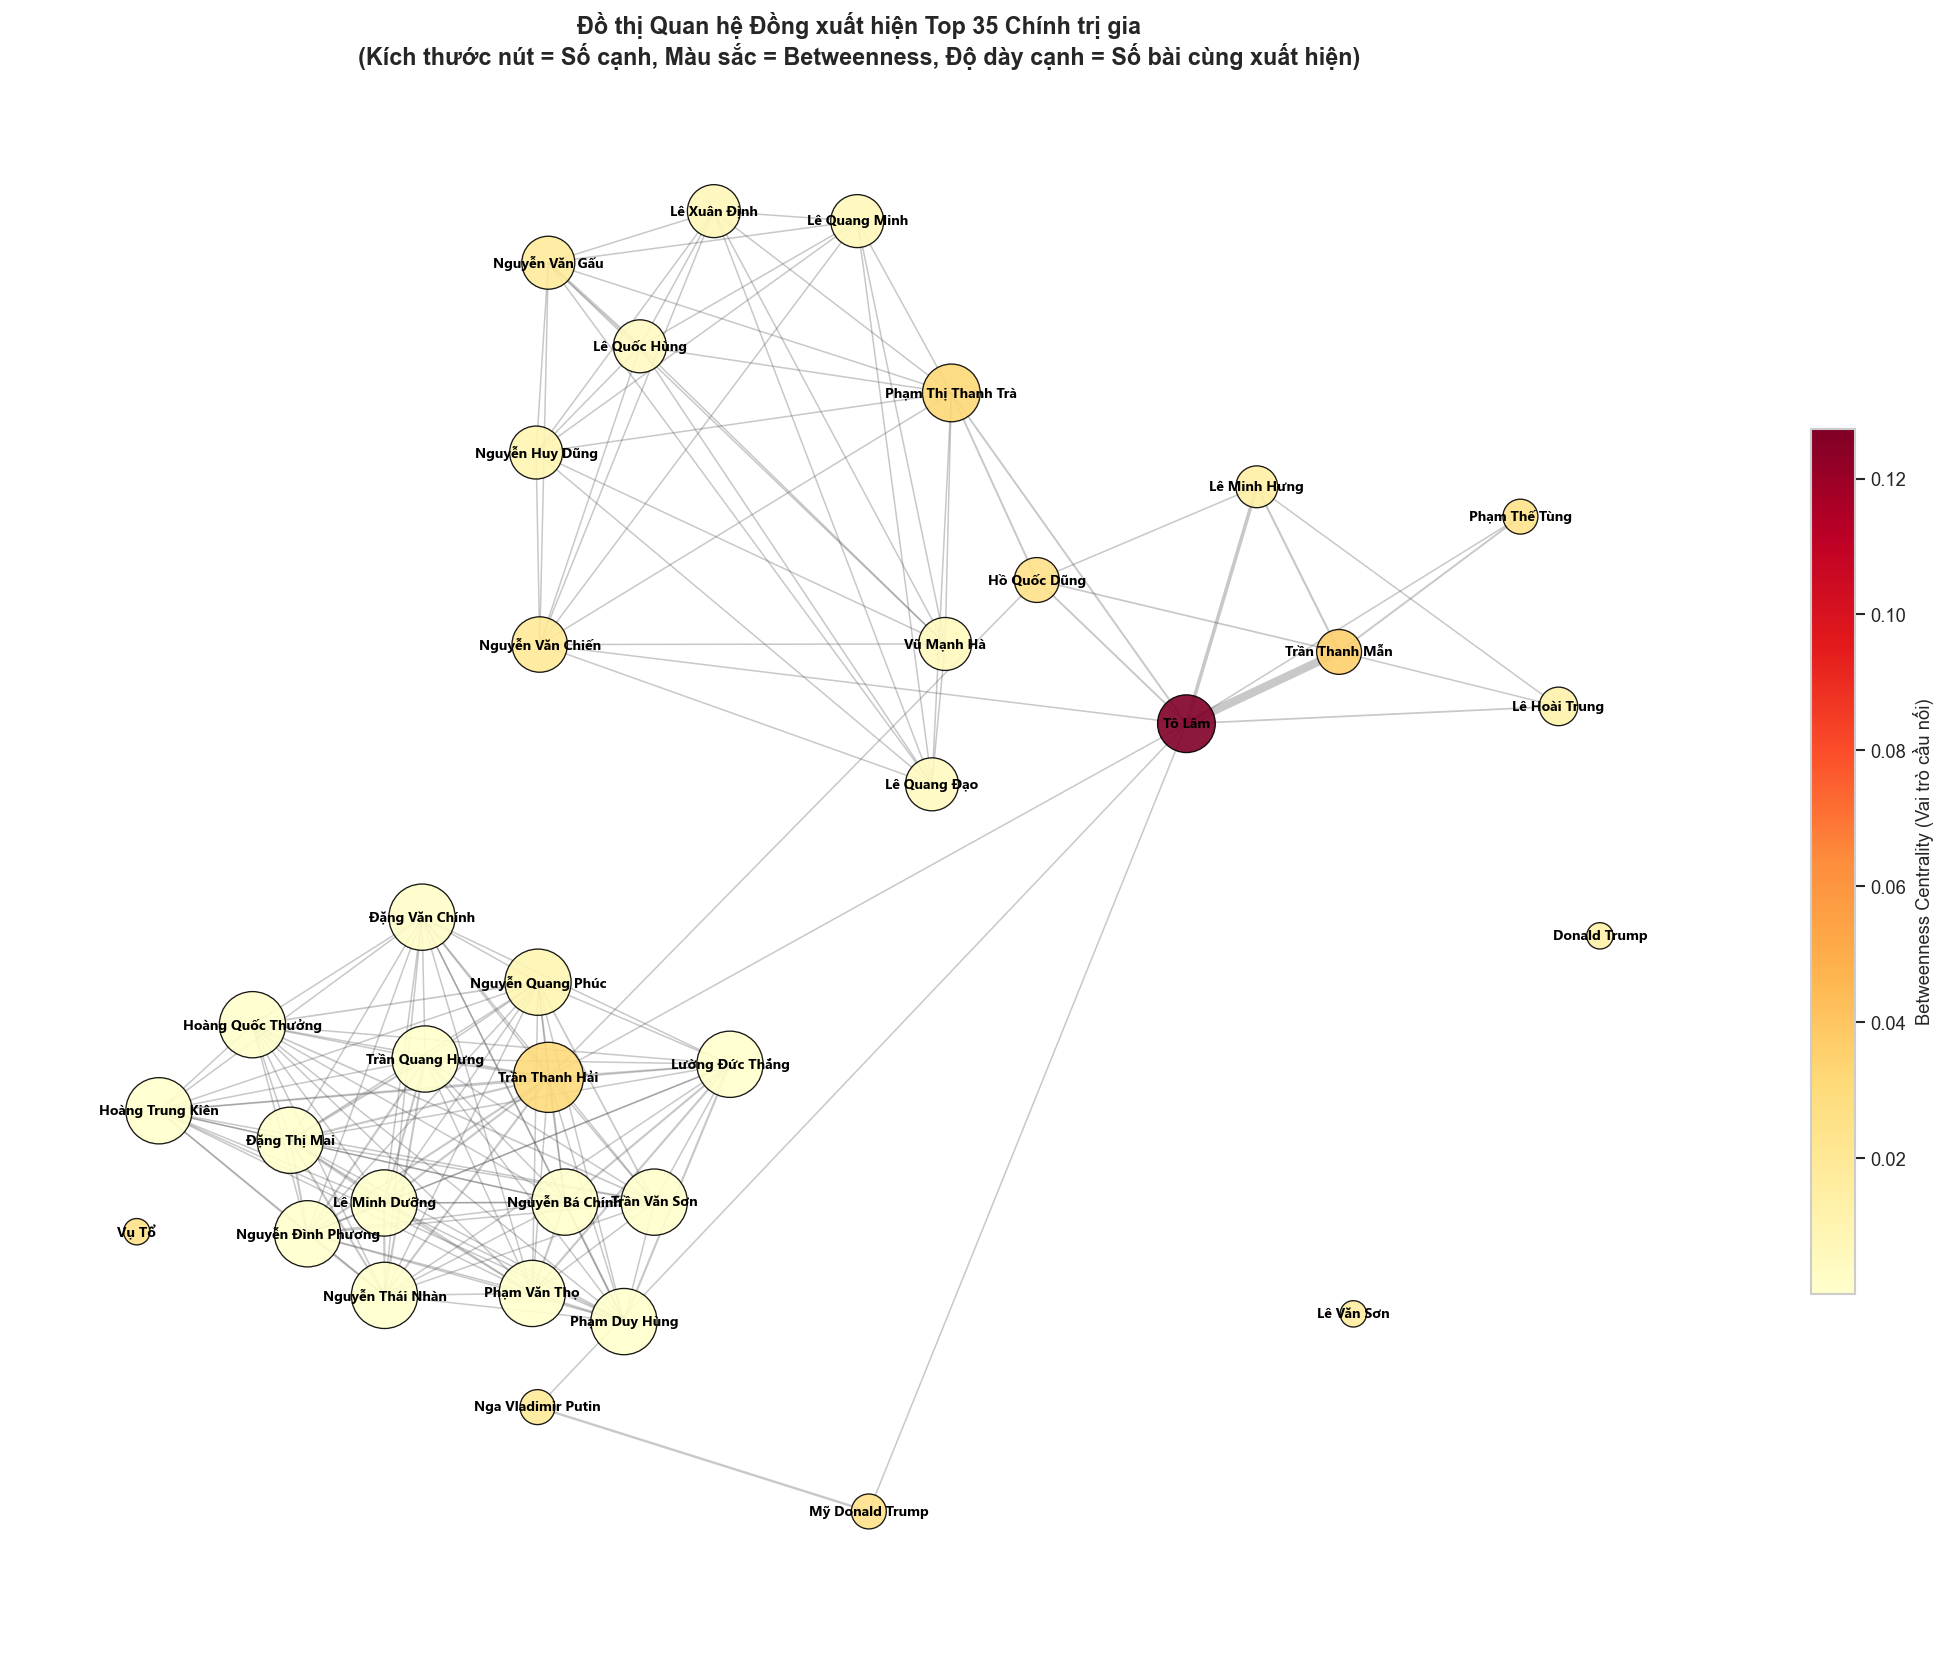

In [12]:
TOP_N = 35
top_nodes = df_graph_metrics.head(TOP_N)['person_name'].tolist()
G_sub = G.subgraph(top_nodes).copy()

pos = nx.spring_layout(G_sub, k=2.2, iterations=100, seed=42, weight='weight')

node_sizes = [G_sub.degree(n) * 95 + 250 for n in G_sub.nodes()]
node_colors = [betweenness_dict.get(n, 0) for n in G_sub.nodes()]
sub_weights = [G_sub[u][v]['weight'] for u, v in G_sub.edges()]
max_sw = max(sub_weights) if sub_weights else 1
edge_widths = [0.8 + 4.2 * (w / max_sw) for w in sub_weights]

fig, ax = plt.subplots(figsize=(18, 14))
nx.draw_networkx_edges(G_sub, pos, width=edge_widths, alpha=0.32, edge_color='#555555', ax=ax)
nx.draw_networkx_nodes(G_sub, pos, node_size=node_sizes, node_color=node_colors,
                       cmap=plt.cm.YlOrRd, edgecolors='black', linewidths=0.8, alpha=0.9, ax=ax)
nx.draw_networkx_labels(G_sub, pos, font_size=8.5, font_weight='bold', font_family='Segoe UI', ax=ax)

sm = plt.cm.ScalarMappable(cmap=plt.cm.YlOrRd, norm=plt.Normalize(vmin=min(node_colors), vmax=max(node_colors)))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.55)
cbar.set_label('Betweenness Centrality (Vai trò cầu nối)', fontsize=11)

ax.set_title(f'Đồ thị Quan hệ Đồng xuất hiện Top {TOP_N} Chính trị gia\n'
             f'(Kích thước nút = Số cạnh, Màu sắc = Betweenness, Độ dày cạnh = Số bài cùng xuất hiện)',
             fontsize=14, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

### 5.6. Đồ thị Ego Network (Mạng lưới liên kết trực tiếp quanh nhân vật có bậc cao nhất)

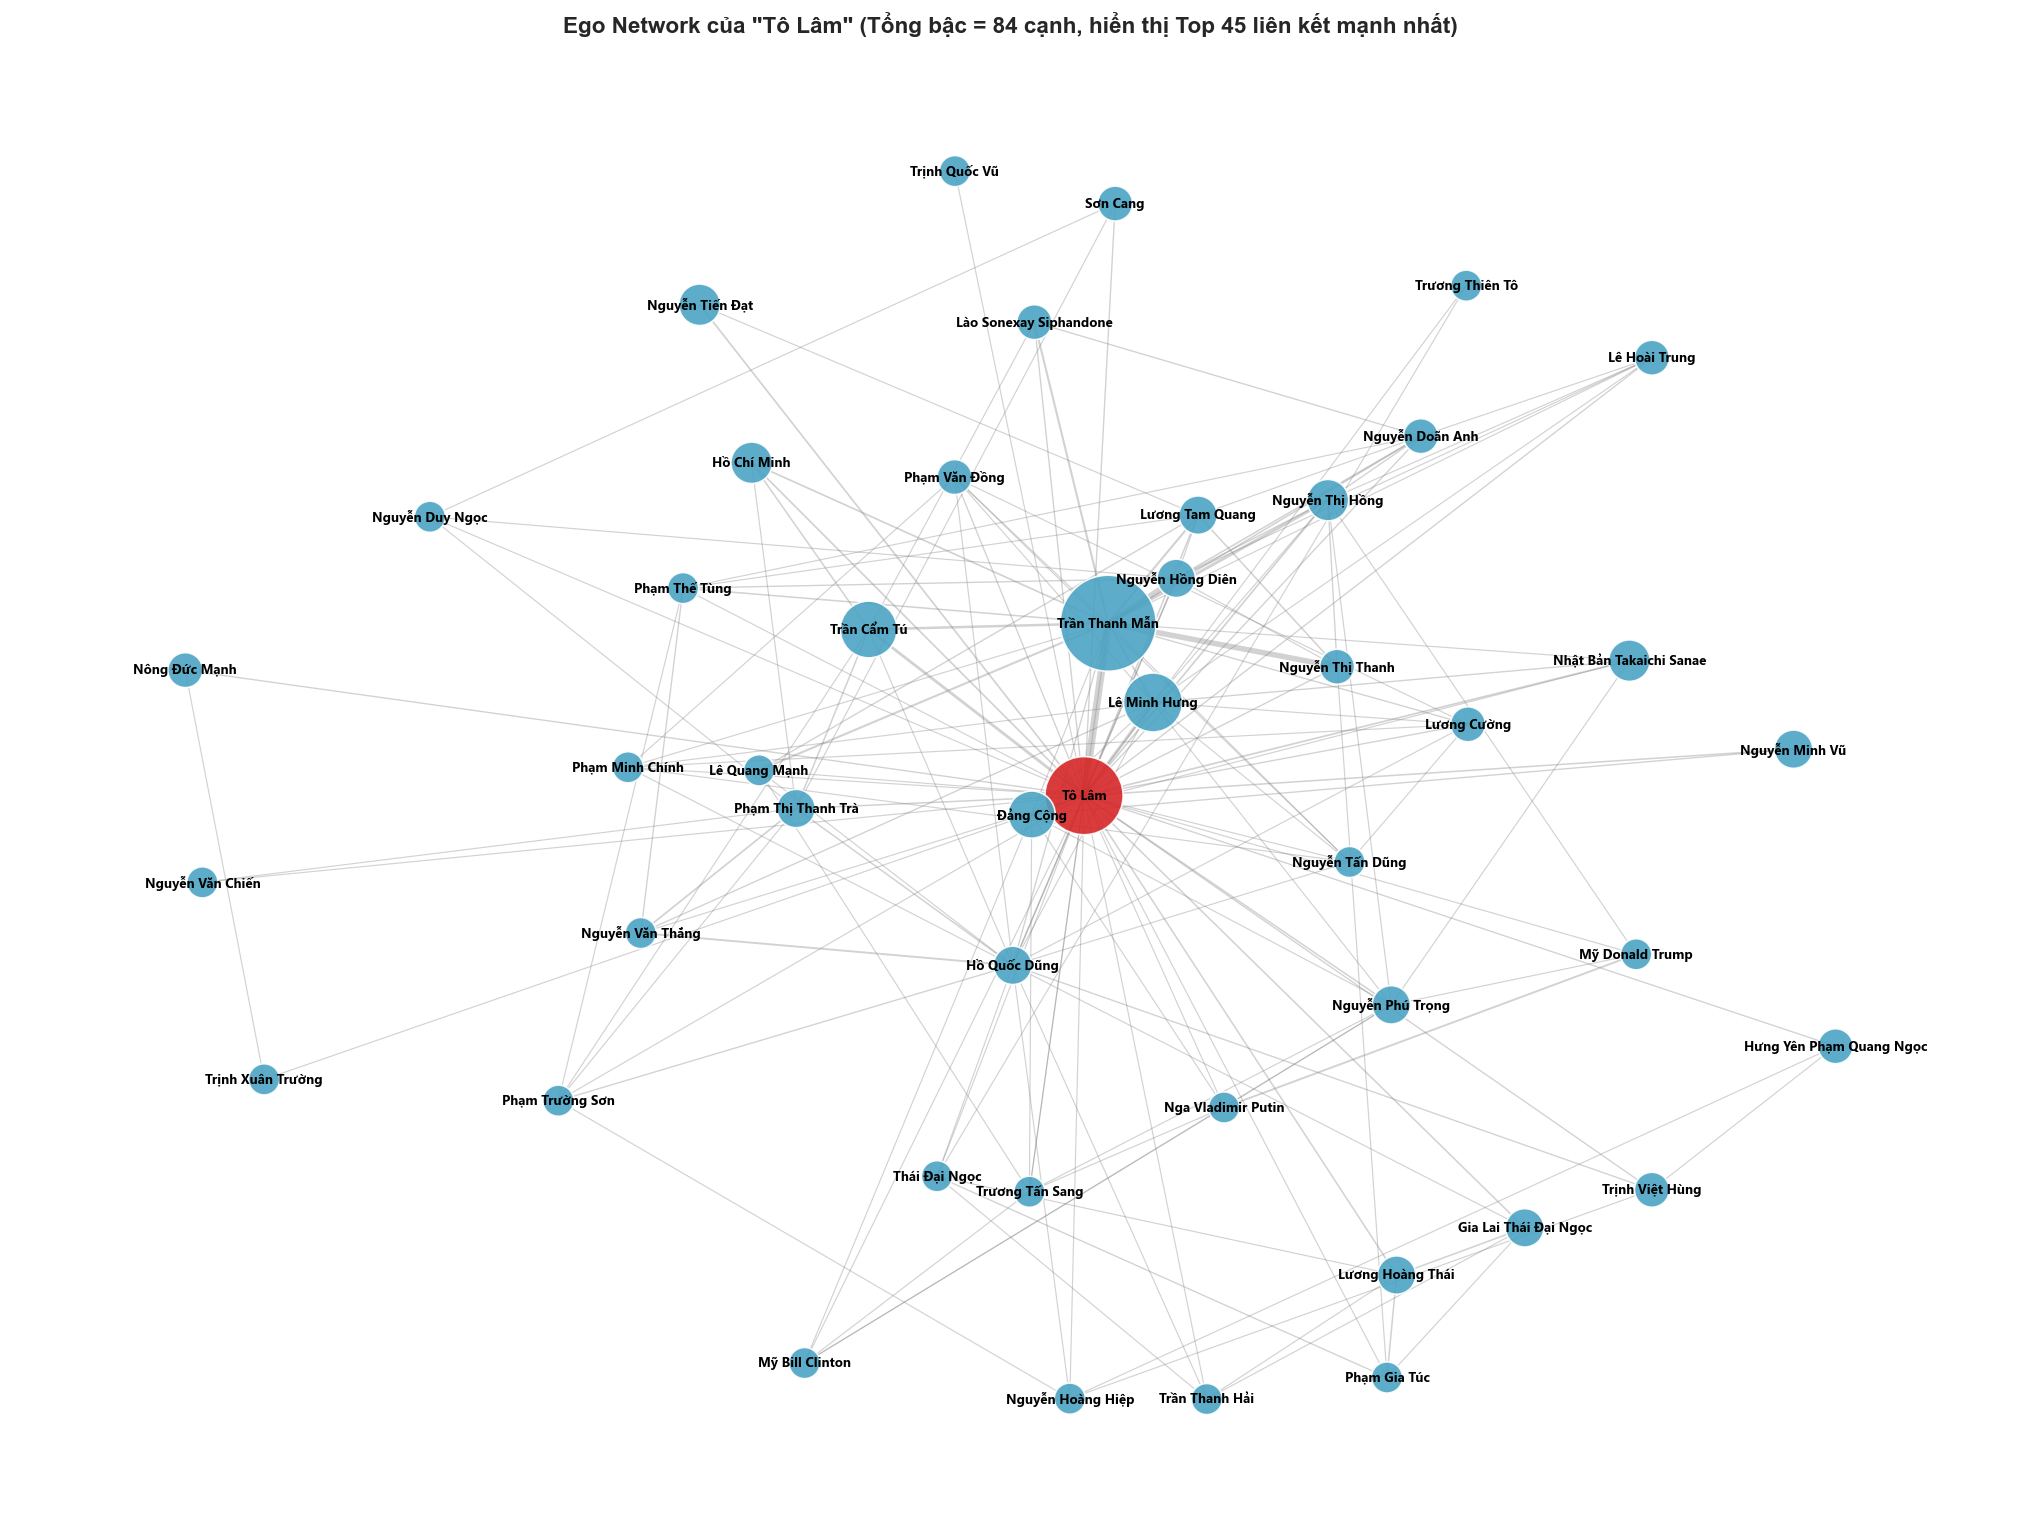

In [13]:
center_person = df_graph_metrics.iloc[0]['person_name']
G_ego = nx.ego_graph(G, center_person, radius=1)

# Nếu số đỉnh quá lớn, lọc giữ lại top 45 láng giềng có trọng số cạnh mạnh nhất với nhân vật trung tâm
neighbors_sorted = sorted(
    [n for n in G_ego.nodes() if n != center_person],
    key=lambda n: (G_ego[center_person][n]['weight'], G.degree(n)),
    reverse=True
)[:45]
G_ego_vis = G_ego.subgraph([center_person] + neighbors_sorted).copy()

pos_ego = nx.spring_layout(G_ego_vis, k=1.9, iterations=80, seed=42)
pos_ego[center_person] = np.array([0.0, 0.0])

ego_sizes = [2200 if n == center_person else 260 + G_ego_vis[center_person][n]['weight'] * 90 for n in G_ego_vis.nodes()]
ego_colors = ['#d62728' if n == center_person else '#4ba3c3' for n in G_ego_vis.nodes()]
ego_weights = [G_ego_vis[u][v]['weight'] for u, v in G_ego_vis.edges()]
max_ew = max(ego_weights) if ego_weights else 1
ego_widths = [0.6 + 3.8 * (w / max_ew) for w in ego_weights]

fig, ax = plt.subplots(figsize=(17, 13))
nx.draw_networkx_edges(G_ego_vis, pos_ego, width=ego_widths, alpha=0.35, edge_color='gray', ax=ax)
nx.draw_networkx_nodes(G_ego_vis, pos_ego, node_size=ego_sizes, node_color=ego_colors,
                       edgecolors='white', linewidths=1.0, alpha=0.9, ax=ax)
nx.draw_networkx_labels(G_ego_vis, pos_ego, font_size=8, font_weight='bold', font_family='Segoe UI', ax=ax)

ax.set_title(f'Ego Network của "{center_person}" (Tổng bậc = {degree_dict[center_person]} cạnh, hiển thị Top {len(neighbors_sorted)} liên kết mạnh nhất)',
             fontsize=13.5, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

### 5.7. Phát hiện Cộng đồng (Community Detection) trong Mạng lưới Chính trị gia

✅ Tổng số cộng đồng phát hiện được: 222 (Modularity Q = 0.8559)


,Cộng đồng,Số thành viên,Nhân vật tiêu biểu (Degree cao nhất)
0,Cộng đồng #1,137,"Tô Lâm (84), Trần Thanh Mẫn (73), Lê Minh Hưng (33), Lê Hoài Trung (21), Nguyễn Thị Thanh (19), Nguyễn Hồng Diên (18)"
1,Cộng đồng #2,107,"Nguyễn Văn Gấu (35), Nguyễn Huy Dũng (25), Lê Quốc Hùng (25), Lê Xuân Định (23), Lê Quang Đạo (22), Lê Quang Minh (22)"
2,Cộng đồng #3,71,"Phạm Thị Thanh Trà (39), Hồ Quốc Dũng (35), Phạm Thế Tùng (23), Nguyễn Văn Thắng (19), Nguyễn Trường Thắng (11), Lê ..."
3,Cộng đồng #4,55,"Mỹ Donald Trump (28), Nga Vladimir Putin (23), Donald Trump (21), Lindsey Graham (11), Joe Biden (10), Mikhail Mishu..."
4,Cộng đồng #5,50,"Vụ Tổ (24), Vụ Khoa (14), Vụ Hợp (13), Trần Đình Hưng (11), Trịnh Văn Cường (11), Trịnh Minh Tâm (11)"
5,Cộng đồng #6,28,"Trần Thanh Hải (29), Nguyễn Bá Chính (23), Phạm Văn Thọ (23), Lường Đức Thắng (23), Phạm Duy Hùng (23), Đặng Văn Chí..."
6,Cộng đồng #7,25,"Ngô Nguyên Phong (18), Nguyễn Văn Nguyên (18), Ngô Văn Huynh (16), Dương Chí Bình (16), Trần Văn Đoan (16), Nguyễn T..."
7,Cộng đồng #8,20,"Lê Văn Sơn (21), Mai Hồng Ngọc (19), Trần Thị Oanh (19), Hoàng Đức Thiện (19), Trần Xuân Quang (19), Nguyễn Văn Ân (19)"
8,Cộng đồng #9,19,"Vũ Mạnh Hà (23), Trịnh Việt Hùng (13), Đào Xuân Cơ (9), Đào Hồng Lan (8), Đỗ Xuân Tuyên (6), Nguyễn Thị Liên Hương (6)"
9,Cộng đồng #10,18,"Cao Sơn Dũng (16), Huỳnh Duy Khôi (16), Trần Hoài Thu (13), Phùng Thị Hương Loan (13), Nguyễn Hồng Thoan (13), Võ Mi..."


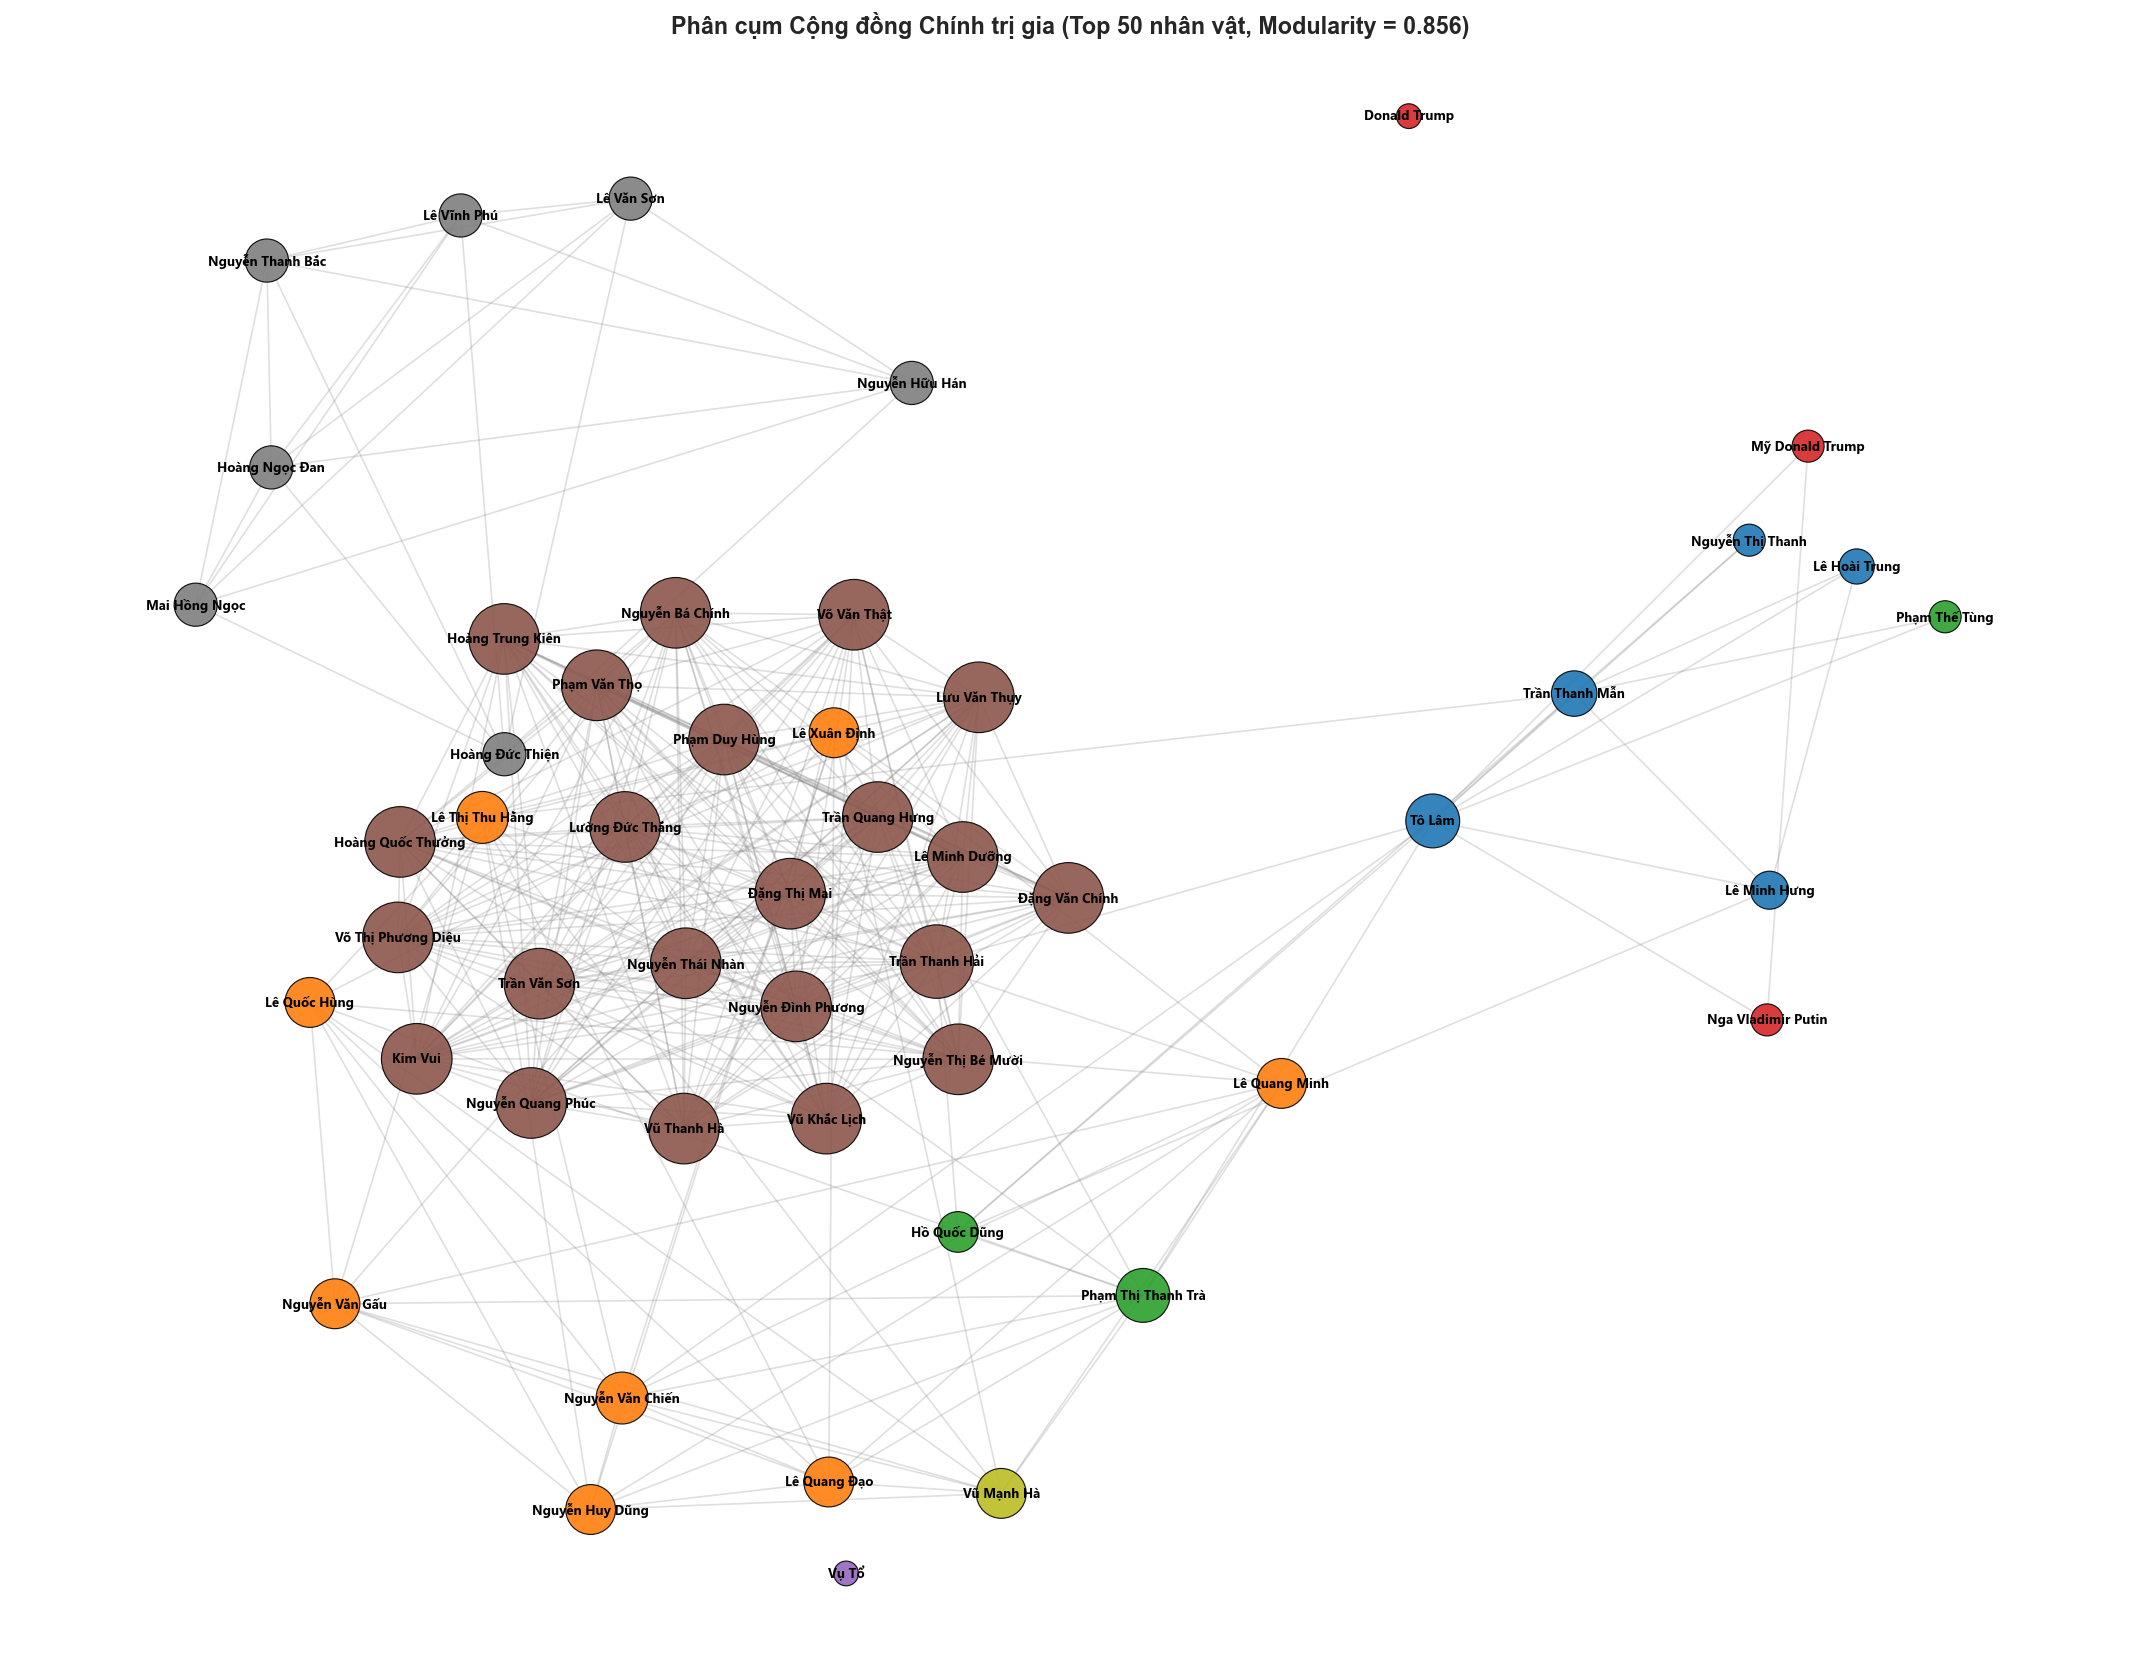

In [14]:
communities = list(nx.community.greedy_modularity_communities(G, weight='weight'))
modularity_score = nx.community.modularity(G, communities, weight='weight')
print(f'✅ Tổng số cộng đồng phát hiện được: {len(communities)} (Modularity Q = {modularity_score:.4f})')

comm_rows = []
node_comm_map = {}
for idx, comm in enumerate(sorted(communities, key=len, reverse=True), start=1):
    for n in comm:
        node_comm_map[n] = idx
    top_members = sorted(comm, key=lambda x: degree_dict.get(x, 0), reverse=True)[:6]
    comm_rows.append({
        'Cộng đồng': f'Cộng đồng #{idx}',
        'Số thành viên': len(comm),
        'Nhân vật tiêu biểu (Degree cao nhất)': ', '.join([f'{m} ({degree_dict[m]})' for m in top_members])
    })

display(pd.DataFrame(comm_rows[:10]))

# Vẽ đồ thị phân cụm cộng đồng trên Top 50 nhân vật
top50_nodes = df_graph_metrics.head(50)['person_name'].tolist()
G_comm = G.subgraph(top50_nodes).copy()
pos_c = nx.spring_layout(G_comm, k=2.1, iterations=90, seed=42)

palette_comm = sns.color_palette('tab10', 10)
node_comm_colors = [palette_comm[(node_comm_map.get(n, 1) - 1) % 10] for n in G_comm.nodes()]
node_comm_sizes = [G_comm.degree(n) * 75 + 220 for n in G_comm.nodes()]

fig, ax = plt.subplots(figsize=(18, 14))
nx.draw_networkx_edges(G_comm, pos_c, alpha=0.25, edge_color='gray', ax=ax)
nx.draw_networkx_nodes(G_comm, pos_c, node_size=node_comm_sizes, node_color=node_comm_colors,
                       edgecolors='black', linewidths=0.7, alpha=0.9, ax=ax)
nx.draw_networkx_labels(G_comm, pos_c, font_size=8, font_weight='bold', font_family='Segoe UI', ax=ax)
ax.set_title(f'Phân cụm Cộng đồng Chính trị gia (Top 50 nhân vật, Modularity = {modularity_score:.3f})', fontsize=14, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

---
## 6. BẢNG TỔNG HỢP KẾT QUẢ PHÂN TÍCH 2 FILE

In [15]:
summary_table = pd.DataFrame([
    ('1. Corpus Bài báo (baomoi_political_corpus.jsonl)', 'Tổng số dòng trong file JSONL', f'{len(df_articles_raw):,}'),
    ('1. Corpus Bài báo (baomoi_political_corpus.jsonl)', 'Số bài báo duy nhất (Unique article_id)', f'{len(df_articles):,}'),
    ('1. Corpus Bài báo (baomoi_political_corpus.jsonl)', 'Số nguồn báo chí (Publishers)', f'{df_articles["publisher"].nunique():,}'),
    ('1. Corpus Bài báo (baomoi_political_corpus.jsonl)', 'Độ dài bài báo trung bình (số từ)', f'{df_articles["content_words"].mean():.1f} từ'),
    ('2. Bảng Nhân vật (baomoi_persons_political_table.json)', 'Tổng số bản ghi nhân vật - bài báo', f'{len(df_persons):,}'),
    ('2. Bảng Nhân vật (baomoi_persons_political_table.json)', 'Số chính trị gia duy nhất (Unique Persons)', f'{df_persons["person_name"].nunique():,}'),
    ('2. Bảng Nhân vật (baomoi_persons_political_table.json)', 'Tổng số lượt nhắc tên (Total Mentions)', f'{df_persons["mention_count"].sum():,}'),
    ('2. Bảng Nhân vật (baomoi_persons_political_table.json)', 'Tổng số câu phát ngôn trực tiếp (Quotes)', f'{df_persons["quotes_count"].sum():,}'),
    ('3. Đồ thị Quan hệ (Co-occurrence Knowledge Graph)', 'Số đỉnh có liên kết (Nodes)', f'{G.number_of_nodes():,}'),
    ('3. Đồ thị Quan hệ (Co-occurrence Knowledge Graph)', 'Số cạnh quan hệ duy nhất (Edges)', f'{G.number_of_edges():,}'),
    ('3. Đồ thị Quan hệ (Co-occurrence Knowledge Graph)', 'Bậc trung bình (Average Degree)', f'{np.mean(degrees):.2f}'),
    ('3. Đồ thị Quan hệ (Co-occurrence Knowledge Graph)', 'Bậc cao nhất (Max Degree)', f'{max(degrees)} ({center_person})'),
    ('3. Đồ thị Quan hệ (Co-occurrence Knowledge Graph)', 'Hệ số phân cụm TB (Avg Clustering)', f'{nx.average_clustering(G):.4f}'),
    ('3. Đồ thị Quan hệ (Co-occurrence Knowledge Graph)', 'Số cộng đồng (Modularity Communities)', f'{len(communities)} (Q = {modularity_score:.4f})'),
], columns=['Nhóm phân tích', 'Chỉ số thống kê', 'Giá trị'])

display(summary_table)

,Nhóm phân tích,Chỉ số thống kê,Giá trị
0,1. Corpus Bài báo (baomoi_political_corpus.jsonl),Tổng số dòng trong file JSONL,"5,325"
1,1. Corpus Bài báo (baomoi_political_corpus.jsonl),Số bài báo duy nhất (Unique article_id),"5,322"
2,1. Corpus Bài báo (baomoi_political_corpus.jsonl),Số nguồn báo chí (Publishers),92
3,1. Corpus Bài báo (baomoi_political_corpus.jsonl),Độ dài bài báo trung bình (số từ),1047.8 từ
4,2. Bảng Nhân vật (baomoi_persons_political_table.json),Tổng số bản ghi nhân vật - bài báo,"3,918"
5,2. Bảng Nhân vật (baomoi_persons_political_table.json),Số chính trị gia duy nhất (Unique Persons),"1,613"
6,2. Bảng Nhân vật (baomoi_persons_political_table.json),Tổng số lượt nhắc tên (Total Mentions),"9,203"
7,2. Bảng Nhân vật (baomoi_persons_political_table.json),Tổng số câu phát ngôn trực tiếp (Quotes),448
8,3. Đồ thị Quan hệ (Co-occurrence Knowledge Graph),Số đỉnh có liên kết (Nodes),"1,172"
9,3. Đồ thị Quan hệ (Co-occurrence Knowledge Graph),Số cạnh quan hệ duy nhất (Edges),"2,561"
